In [1]:
import pandas as pd
from google.colab import files

uploaded = files.upload()
file_name = list(uploaded.keys())[0]

df = pd.read_excel(file_name)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nNumber of species:", df["Species"].nunique())

print("\nSpecies distribution:")
print(df["Species"].value_counts())

Saving spider dataset for ml.xlsx to spider dataset for ml.xlsx
Dataset shape: (1721, 38)

Columns:
['Species', 'Body length (mm)', 'Prosoma Length (mm)', 'Prosoma width (mm)', 'Prosoma Shape', 'Carapace Marking', 'Abdomen', 'Abdomen Shape', 'Abdominal Folium Pattern', 'Eye Pattern', 'Anterior Eye Row', 'Posterior Eye Row', 'Eye Row Curvature', 'Eye Spacing', 'Chelicera Shape', 'Cheliceral Teeth Count (total per chelicera)', 'Promarginal Teeth Count', 'Retromarginal Teeth Count', 'Leg Formula', 'Leg Spination Density', 'Femur Spines', 'Tibia Spines', 'Metatarsus Spines', 'Scopula Presence', 'Scopula Distribution', 'Trichobothria Pattern', 'Tarsal Claw Number', 'Tarsal Claw Teeth', 'Spinneret Type', 'Spinneret Segmentation', 'Spinneret Arrangement', 'Sternum Shape', 'Epigyne Shape', 'Epigyne Structure', 'Copulatory Opening Position', 'Copulatory Duct Shape', 'Spermathecae Shape', 'Spermathecae Spacing']

Missing values:
Leg Spination Density    276
dtype: int64

Number of species: 45

S

In [3]:
import numpy as np

def midpoint(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().replace("–", "-").replace("—", "-")

    if x.upper() == "NR" or x == "":
        return np.nan

    if "-" in x:
        a, b = x.split("-", 1)
        try:
            return (float(a.strip()) + float(b.strip())) / 2
        except:
            return np.nan

    try:
        return float(x)
    except:
        return np.nan

# Convert measurement ranges to numerical midpoints
for col in ["Body length (mm)", "Prosoma Length (mm)", "Prosoma width (mm)"]:
    df[col] = df[col].apply(midpoint)

# Remove constant variable
if df["Tarsal Claw Number"].nunique(dropna=True) <= 1:
    df = df.drop(columns=["Tarsal Claw Number"])

print("Dataset shape:", df.shape)

print("\nMissing values after conversion:")
print(df.isna().sum()[df.isna().sum() > 0])

Dataset shape: (1721, 37)

Missing values after conversion:
Prosoma Length (mm)       51
Prosoma width (mm)        91
Leg Spination Density    276
dtype: int64


In [4]:
# Cell 3 — Define target and predictors

X = df.drop(columns=["Species"])
y = df["Species"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget classes:", y.nunique())
print("Predictor variables:", X.shape[1])

print("\nPredictor columns:")
print(X.columns.tolist())

X shape: (1721, 36)
y shape: (1721,)

Target classes: 45
Predictor variables: 36

Predictor columns:
['Body length (mm)', 'Prosoma Length (mm)', 'Prosoma width (mm)', 'Prosoma Shape', 'Carapace Marking', 'Abdomen', 'Abdomen Shape', 'Abdominal Folium Pattern', 'Eye Pattern', 'Anterior Eye Row', 'Posterior Eye Row', 'Eye Row Curvature', 'Eye Spacing', 'Chelicera Shape', 'Cheliceral Teeth Count (total per chelicera)', 'Promarginal Teeth Count', 'Retromarginal Teeth Count', 'Leg Formula', 'Leg Spination Density', 'Femur Spines', 'Tibia Spines', 'Metatarsus Spines', 'Scopula Presence', 'Scopula Distribution', 'Trichobothria Pattern', 'Tarsal Claw Teeth', 'Spinneret Type', 'Spinneret Segmentation', 'Spinneret Arrangement', 'Sternum Shape', 'Epigyne Shape', 'Epigyne Structure', 'Copulatory Opening Position', 'Copulatory Duct Shape', 'Spermathecae Shape', 'Spermathecae Spacing']


In [5]:
# Cell 4 — Train/Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining species:", y_train.nunique())
print("Testing species:", y_test.nunique())

Training samples: 1376
Testing samples: 345

Training species: 45
Testing species: 45


In [6]:
# Cell 5 — Identify numerical and categorical features

import numpy as np

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", len(numeric_features))
print(numeric_features)

print("\nCategorical features:", len(categorical_features))
print(categorical_features)

Numerical features: 6
['Body length (mm)', 'Prosoma Length (mm)', 'Prosoma width (mm)', 'Cheliceral Teeth Count (total per chelicera)', 'Promarginal Teeth Count', 'Retromarginal Teeth Count']

Categorical features: 30
['Prosoma Shape', 'Carapace Marking', 'Abdomen', 'Abdomen Shape', 'Abdominal Folium Pattern', 'Eye Pattern', 'Anterior Eye Row', 'Posterior Eye Row', 'Eye Row Curvature', 'Eye Spacing', 'Chelicera Shape', 'Leg Formula', 'Leg Spination Density', 'Femur Spines', 'Tibia Spines', 'Metatarsus Spines', 'Scopula Presence', 'Scopula Distribution', 'Trichobothria Pattern', 'Tarsal Claw Teeth', 'Spinneret Type', 'Spinneret Segmentation', 'Spinneret Arrangement', 'Sternum Shape', 'Epigyne Shape', 'Epigyne Structure', 'Copulatory Opening Position', 'Copulatory Duct Shape', 'Spermathecae Shape', 'Spermathecae Spacing']


In [7]:
# Cell 6 — Preprocessing

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Preprocessing pipeline created successfully.
Numerical features: 6
Categorical features: 30


In [8]:
# Cell 7 — Decision Tree

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        max_depth=12,
        min_samples_leaf=2
    ))
])

dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)

accuracy_dt = accuracy_score(y_test, y_pred_dt)

print(f"Decision Tree Accuracy: {accuracy_dt:.4f} ({accuracy_dt*100:.2f}%)")

Decision Tree Accuracy: 0.5565 (55.65%)


In [9]:
# Cell 8 — Decision Tree tuning

from sklearn.model_selection import GridSearchCV

dt_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

param_grid = {
    "classifier__max_depth": [None, 10, 15, 20, 25],
    "classifier__min_samples_leaf": [1, 2, 3, 5]
}

dt_grid = GridSearchCV(
    dt_pipe,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best parameters:", dt_grid.best_params_)
print(f"Best CV accuracy: {dt_grid.best_score_:.4f}")

y_pred_dt = dt_grid.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")

Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 5}
Best CV accuracy: 0.9891
Test accuracy: 0.9826


In [10]:
# ============================================================
# CELL 9 — NORMALIZED CONFUSION MATRIX
# DECISION TREE
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred_dt,
    labels=dt_grid.classes_,
    normalize="true"
)

species = dt_grid.classes_

plt.figure(figsize=(24, 21), dpi=300)

ax = sns.heatmap(
    cm,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    square=True,
    xticklabels=species,
    yticklabels=species,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Proportion",
        "shrink": 0.85
    },
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    }
)

# Species names — X axis
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Species names — Y axis
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Axis labels
ax.set_xlabel(
    "Predicted Species",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "True Species",
    fontsize=20,
    fontweight="bold"
)

# Colorbar
cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=13
)

cbar.set_label(
    "Proportion",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

# Save
plt.savefig(
    "Normalized_Confusion_Matrix_Decision_Tree.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Normalized_Confusion_Matrix_Decision_Tree.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [11]:
# ============================================================
# CELL 10 — K-NEAREST NEIGHBORS (KNN)
# ============================================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

knn_accuracy = accuracy_score(y_test, y_pred_knn)

print(f"KNN Accuracy: {knn_accuracy:.4f} ({knn_accuracy*100:.2f}%)")

KNN Accuracy: 0.8145 (81.45%)


In [12]:
# ============================================================
# CELL 11 — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

lr_accuracy = accuracy_score(y_test, y_pred_lr)

print(f"Logistic Regression Accuracy: {lr_accuracy:.4f} ({lr_accuracy*100:.2f}%)")

Logistic Regression Accuracy: 0.9884 (98.84%)


In [13]:
# ============================================================
# CELL 12 — RANDOM FOREST + NORMALIZED CONFUSION MATRIX
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Random Forest
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print(f"Random Forest Accuracy: {rf_accuracy:.4f} ({rf_accuracy*100:.2f}%)")

# ------------------------------------------------------------
# NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

cm_rf = confusion_matrix(
    y_test,
    y_pred_rf,
    labels=rf_model.classes_,
    normalize="true"
)

species = rf_model.classes_

plt.figure(figsize=(24, 21), dpi=300)

ax = sns.heatmap(
    cm_rf,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    square=True,
    xticklabels=species,
    yticklabels=species,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Proportion",
        "shrink": 0.85
    },
    annot_kws={
        "fontsize": 10,
        "fontweight": "bold"
    }
)

# Species names — X axis
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Species names — Y axis
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Axis labels
ax.set_xlabel(
    "Predicted Species",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "True Species",
    fontsize=20,
    fontweight="bold"
)

# Colorbar
cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=13
)

cbar.set_label(
    "Proportion",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

# Save
plt.savefig(
    "Normalized_Confusion_Matrix_Random_Forest.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Normalized_Confusion_Matrix_Random_Forest.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# ============================================================
# KNN — NORMALIZED CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_knn = confusion_matrix(
    y_test,
    y_pred_knn,
    labels=knn_model.classes_,
    normalize="true"
)

species = knn_model.classes_

plt.figure(figsize=(24, 21), dpi=300)

ax = sns.heatmap(
    cm_knn,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    square=True,
    xticklabels=species,
    yticklabels=species,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Proportion", "shrink": 0.85},
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

ax.set_xlabel("Predicted Species", fontsize=20, fontweight="bold")
ax.set_ylabel("True Species", fontsize=20, fontweight="bold")

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=13)
cbar.set_label("Proportion", fontsize=18, fontweight="bold")

plt.tight_layout()

plt.savefig("Normalized_Confusion_Matrix_KNN.png",
            dpi=600, bbox_inches="tight")
plt.savefig("Normalized_Confusion_Matrix_KNN.pdf",
            dpi=600, bbox_inches="tight")

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [15]:
# ============================================================
# LOGISTIC REGRESSION — NORMALIZED CONFUSION MATRIX
# ============================================================

cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=lr_model.classes_,
    normalize="true"
)

species = lr_model.classes_

plt.figure(figsize=(24, 21), dpi=300)

ax = sns.heatmap(
    cm_lr,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    square=True,
    xticklabels=species,
    yticklabels=species,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Proportion", "shrink": 0.85},
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

ax.set_xlabel("Predicted Species", fontsize=20, fontweight="bold")
ax.set_ylabel("True Species", fontsize=20, fontweight="bold")

cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=13)
cbar.set_label("Proportion", fontsize=18, fontweight="bold")

plt.tight_layout()

plt.savefig("Normalized_Confusion_Matrix_Logistic_Regression.png",
            dpi=600, bbox_inches="tight")
plt.savefig("Normalized_Confusion_Matrix_Logistic_Regression.pdf",
            dpi=600, bbox_inches="tight")

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [16]:
# ============================================================
# CELL 13 — SVM + CONFUSION MATRIX
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print(
    f"SVM Accuracy: {svm_accuracy:.4f} "
    f"({svm_accuracy*100:.2f}%)"
)

# ------------------------------------------------------------
# NORMALIZED CONFUSION MATRIX
# ------------------------------------------------------------

cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=svm_model.classes_,
    normalize="true"
)

plt.figure(figsize=(24, 21), dpi=300)

ax = sns.heatmap(
    cm_svm,
    cmap="Blues",
    annot=True,
    fmt=".2f",
    square=True,
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_,
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Proportion", "shrink": 0.85},
    annot_kws={"fontsize": 10, "fontweight": "bold"}
)

# Species names — X axis
ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=90,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Species names — Y axis
ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0,
    fontsize=17,
    fontweight="bold",
    fontstyle="italic"
)

# Axis labels
ax.set_xlabel(
    "Predicted Species",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "True Species",
    fontsize=20,
    fontweight="bold"
)

# Colorbar
cbar = ax.collections[0].colorbar

cbar.ax.tick_params(
    labelsize=13
)

cbar.set_label(
    "Proportion",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()

# Save
plt.savefig(
    "Normalized_Confusion_Matrix_SVM.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Normalized_Confusion_Matrix_SVM.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [17]:
# ============================================================
# CELL 14 — MODEL ACCURACY SUMMARY
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "KNN",
        "Logistic Regression",
        "Random Forest",
        "SVM"
    ],
    "Accuracy (%)": [
        accuracy_score(y_test, y_pred_dt) * 100,
        accuracy_score(y_test, y_pred_knn) * 100,
        accuracy_score(y_test, y_pred_lr) * 100,
        accuracy_score(y_test, y_pred_rf) * 100,
        accuracy_score(y_test, y_pred_svm) * 100
    ]
})

results["Accuracy (%)"] = results["Accuracy (%)"].round(2)

display(results.sort_values("Accuracy (%)", ascending=False))

,Model,Accuracy (%)
2,Logistic Regression,98.84
3,Random Forest,98.84
0,Decision Tree,98.26
4,SVM,95.36
1,KNN,81.45


In [18]:
# ============================================================
# CELL 15 — OOF PREDICTIONS
# ============================================================

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

oof_results = {}

for name, model in models.items():
    print(f"Running OOF: {name}")

    pred = cross_val_predict(
        model,
        X_train,
        y_train,
        cv=cv,
        method="predict",
        n_jobs=-1
    )

    oof_results[name] = pred

    print(
        f"OOF Accuracy: "
        f"{accuracy_score(y_train, pred)*100:.2f}%"
    )

print("\nOOF analysis completed.")

Running OOF: Decision Tree
OOF Accuracy: 98.91%
Running OOF: KNN
OOF Accuracy: 83.21%
Running OOF: Logistic Regression
OOF Accuracy: 96.51%
Running OOF: Random Forest
OOF Accuracy: 98.40%
Running OOF: SVM
OOF Accuracy: 93.97%

OOF analysis completed.


In [19]:
# ============================================================
# CELL 16 — OOF PERFORMANCE METRICS
# ============================================================

from sklearn.metrics import precision_score, recall_score, f1_score

oof_metrics = []

for name, pred in oof_results.items():

    oof_metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_train, pred),
        "Macro Precision": precision_score(y_train, pred, average="macro"),
        "Macro Recall": recall_score(y_train, pred, average="macro"),
        "Macro F1": f1_score(y_train, pred, average="macro")
    })

oof_metrics = pd.DataFrame(oof_metrics)

oof_metrics[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
] = oof_metrics[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
].round(4)

display(oof_metrics)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Decision Tree,0.9891,0.9889,0.9886,0.9884
1,KNN,0.8321,0.8333,0.8213,0.8207
2,Logistic Regression,0.9651,0.9662,0.9620,0.9630
3,Random Forest,0.9840,0.9843,0.9831,0.9835
4,SVM,0.9397,0.9321,0.9338,0.9281


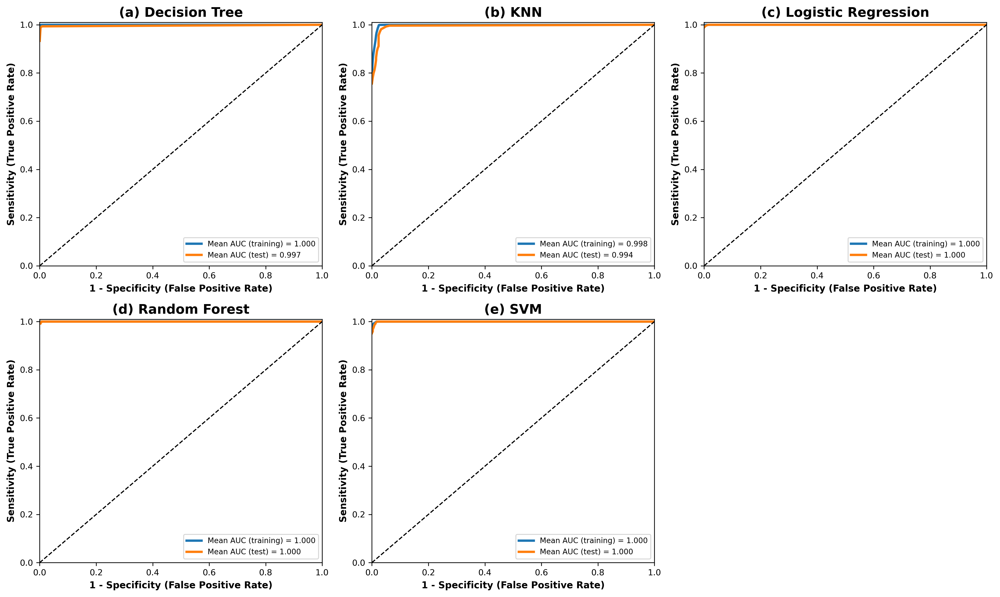

In [20]:
# ============================================================
# CELL 17 — MACRO-AVERAGE ROC: TRAINING vs TESTING
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

letters = ["(a)", "(b)", "(c)", "(d)", "(e)"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    dpi=300
)

axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    ax = axes[i]
    classes = model.classes_

    def macro_roc(X_data, y_data):

        y_bin = label_binarize(
            y_data,
            classes=classes
        )

        y_prob = model.predict_proba(X_data)

        fpr = {}
        tpr = {}

        for j in range(len(classes)):
            fpr[j], tpr[j], _ = roc_curve(
                y_bin[:, j],
                y_prob[:, j]
            )

        all_fpr = np.unique(
            np.concatenate(
                [fpr[j] for j in range(len(classes))]
            )
        )

        mean_tpr = np.zeros_like(all_fpr)

        for j in range(len(classes)):
            mean_tpr += np.interp(
                all_fpr,
                fpr[j],
                tpr[j]
            )

        mean_tpr /= len(classes)

        macro_auc = auc(
            all_fpr,
            mean_tpr
        )

        return all_fpr, mean_tpr, macro_auc

    # Training
    fpr_train, tpr_train, auc_train = macro_roc(
        X_train,
        y_train
    )

    # Testing
    fpr_test, tpr_test, auc_test = macro_roc(
        X_test,
        y_test
    )

    # Training curve
    ax.plot(
        fpr_train,
        tpr_train,
        linewidth=2.5,
        label=f"Mean AUC (training) = {auc_train:.3f}"
    )

    # Testing curve
    ax.plot(
        fpr_test,
        tpr_test,
        linewidth=2.5,
        label=f"Mean AUC (test) = {auc_test:.3f}"
    )

    # Random classifier
    ax.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.2
    )

    ax.set_title(
        f"{letters[i]} {name}",
        fontsize=14,
        fontweight="bold"
    )

    ax.set_xlabel(
        "1 - Specificity (False Positive Rate)",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Sensitivity (True Positive Rate)",
        fontsize=10,
        fontweight="bold"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)

    ax.tick_params(
        labelsize=9
    )

    ax.legend(
        loc="lower right",
        fontsize=8,
        frameon=True
    )

# Remove empty sixth panel
axes[5].axis("off")

plt.tight_layout()

plt.savefig(
    "ROC_Macro_AUC_Train_Test.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_Macro_AUC_Train_Test.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

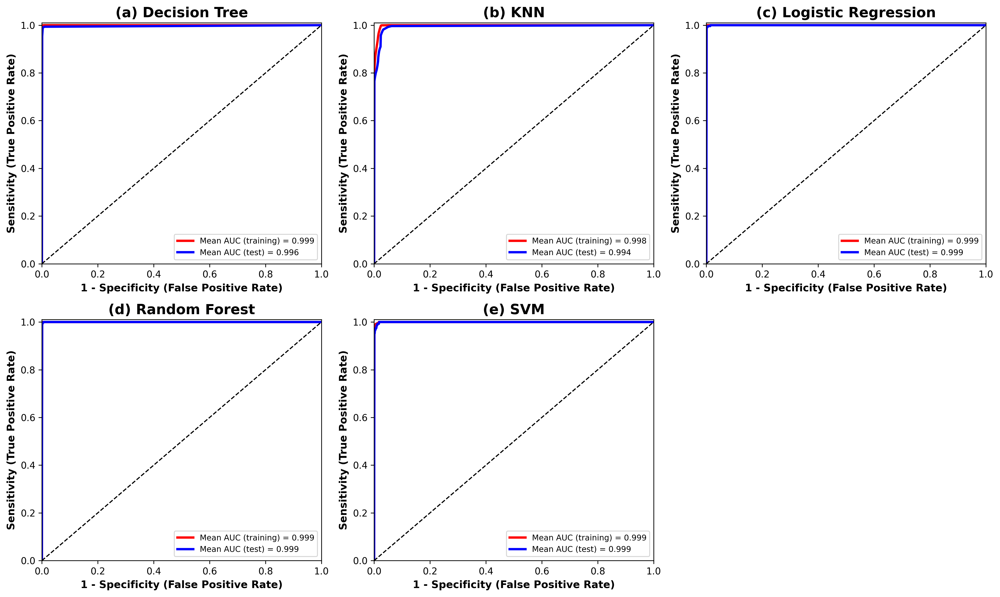

In [21]:
# ============================================================
# CELL 17 — FINAL MACRO-AVERAGE ROC CURVES
# TRAINING vs TESTING
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

letters = ["(a)", "(b)", "(c)", "(d)", "(e)"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9),
    dpi=300
)

axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):

    ax = axes[i]
    classes = model.classes_

    def calculate_macro_roc(X_data, y_data):

        y_bin = label_binarize(
            y_data,
            classes=classes
        )

        y_prob = model.predict_proba(X_data)

        fpr_grid = np.linspace(0, 1, 1000)

        tpr_list = []

        for j in range(len(classes)):

            fpr, tpr, _ = roc_curve(
                y_bin[:, j],
                y_prob[:, j]
            )

            tpr_interp = np.interp(
                fpr_grid,
                fpr,
                tpr
            )

            tpr_list.append(tpr_interp)

        mean_tpr = np.mean(
            tpr_list,
            axis=0
        )

        mean_tpr[0] = 0
        mean_tpr[-1] = 1

        macro_auc = auc(
            fpr_grid,
            mean_tpr
        )

        return fpr_grid, mean_tpr, macro_auc

    # Training
    fpr_train, tpr_train, auc_train = calculate_macro_roc(
        X_train,
        y_train
    )

    # Testing
    fpr_test, tpr_test, auc_test = calculate_macro_roc(
        X_test,
        y_test
    )

    # --------------------------------------------------------
    # TRAINING — RED
    # --------------------------------------------------------

    ax.plot(
        fpr_train,
        tpr_train,
        color="red",
        linewidth=2.5,
        label=f"Mean AUC (training) = {auc_train:.3f}"
    )

    # --------------------------------------------------------
    # TESTING — BLUE
    # --------------------------------------------------------

    ax.plot(
        fpr_test,
        tpr_test,
        color="blue",
        linewidth=2.5,
        label=f"Mean AUC (test) = {auc_test:.3f}"
    )

    # Chance line
    ax.plot(
        [0, 1],
        [0, 1],
        color="black",
        linestyle="--",
        linewidth=1.2
    )

    # --------------------------------------------------------
    # FORMATTING
    # --------------------------------------------------------

    ax.set_title(
        f"{letters[i]} {name}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "1 - Specificity (False Positive Rate)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "Sensitivity (True Positive Rate)",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)

    ax.tick_params(
        labelsize=10
    )

    ax.legend(
        loc="lower right",
        fontsize=8.5,
        frameon=True
    )


# Remove empty sixth panel
axes[5].axis("off")

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

plt.savefig(
    "Final_ROC_Macro_AUC_Train_Test.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Final_ROC_Macro_AUC_Train_Test.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [22]:
# ============================================================
# CELL 18 — FEATURE IMPORTANCE
# DECISION TREE
# ============================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

result = permutation_importance(
    dt_grid.best_estimator_,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("Top 15 important characters:")
display(importance.head(15))

Top 15 important characters:


,Feature,Importance
17,Leg Formula,0.374783
12,Eye Spacing,0.276522
2,Prosoma width (mm),0.255652
34,Spermathecae Shape,0.166087
5,Abdomen,0.155072
27,Spinneret Segmentation,0.150435
0,Body length (mm),0.128696
20,Tibia Spines,0.126667
1,Prosoma Length (mm),0.123768
24,Trichobothria Pattern,0.100580


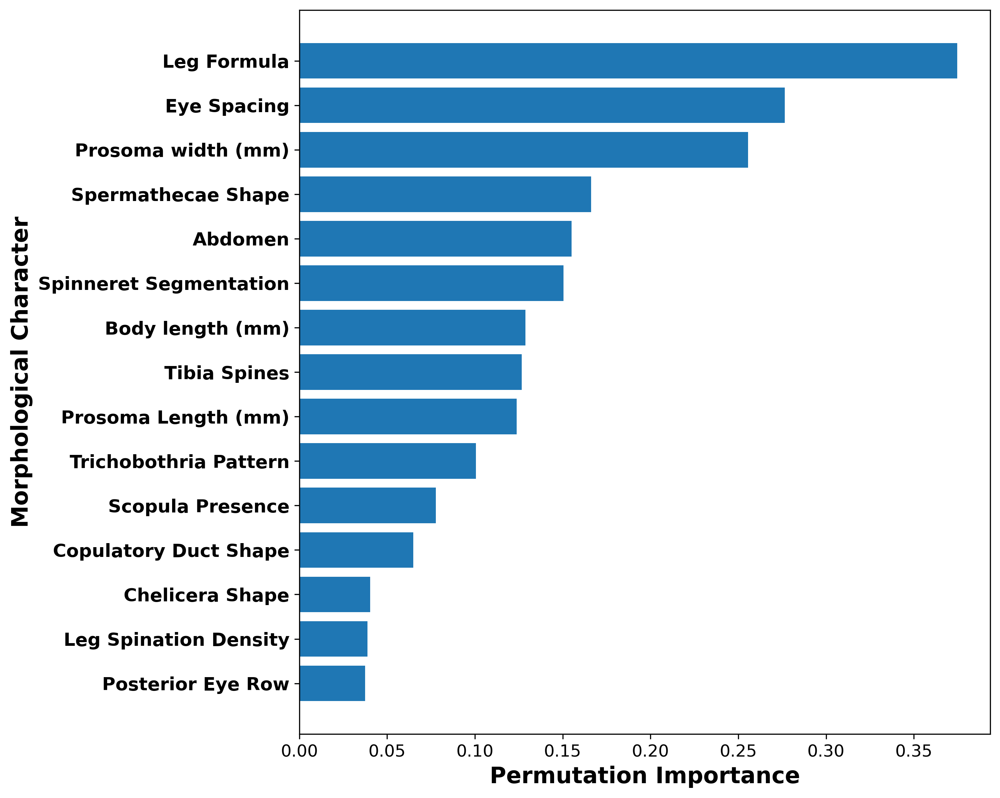

In [23]:
# ============================================================
# CELL 19 — FEATURE IMPORTANCE PLOT
# ============================================================

top = importance.head(15).sort_values("Importance")

plt.figure(figsize=(10, 8), dpi=300)

plt.barh(
    top["Feature"],
    top["Importance"]
)

plt.xlabel(
    "Permutation Importance",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel(
    "Morphological Character",
    fontsize=16,
    fontweight="bold"
)

plt.xticks(fontsize=12)
plt.yticks(
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Decision_Tree_Feature_Importance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Decision_Tree_Feature_Importance.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

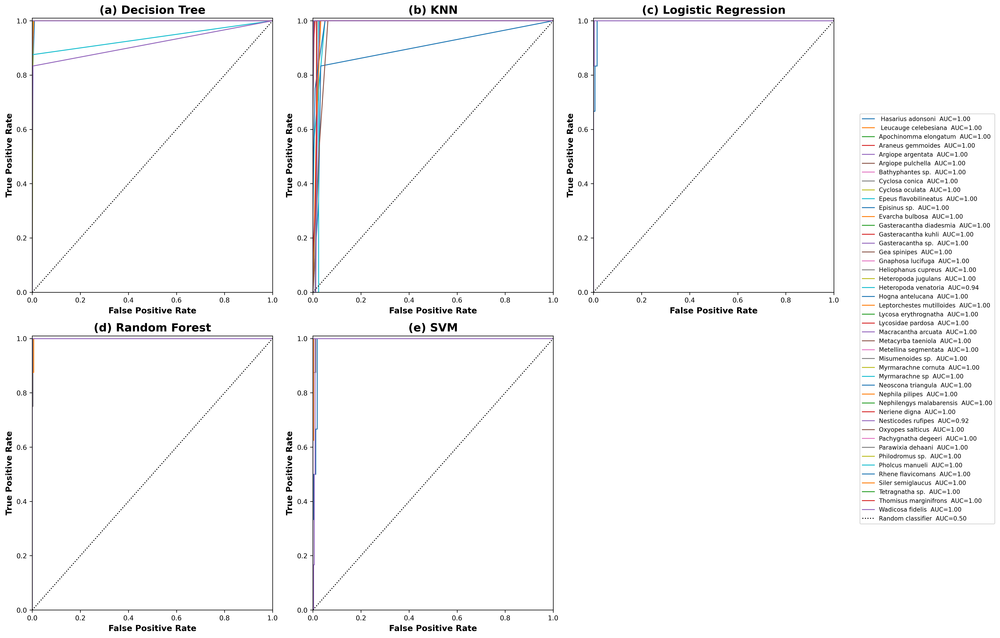

In [24]:
# ============================================================
# CELL 20 — SPECIES-LEVEL MULTICLASS ROC
# ALL FIVE MODELS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import numpy as np
import matplotlib.pyplot as plt

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

letters = ["(a)", "(b)", "(c)", "(d)", "(e)"]

fig, axes = plt.subplots(
    2, 3,
    figsize=(18, 12),
    dpi=300
)

axes = axes.flatten()

auc_results = {}

for panel, (name, model) in enumerate(models.items()):

    ax = axes[panel]

    classes = model.classes_

    y_bin = label_binarize(
        y_test,
        classes=classes
    )

    y_prob = model.predict_proba(X_test)

    auc_results[name] = {}

    for i, species in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_bin[:, i],
            y_prob[:, i]
        )

        roc_auc = auc(fpr, tpr)

        auc_results[name][species] = roc_auc

        ax.plot(
            fpr,
            tpr,
            linewidth=1.2,
            label=f"{species}  AUC={roc_auc:.2f}"
        )

    # Random classifier
    ax.plot(
        [0, 1],
        [0, 1],
        "k:",
        linewidth=1.3,
        label="Random classifier  AUC=0.50"
    )

    ax.set_title(
        f"{letters[panel]} {name}",
        fontsize=15,
        fontweight="bold"
    )

    ax.set_xlabel(
        "False Positive Rate",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_ylabel(
        "True Positive Rate",
        fontsize=11,
        fontweight="bold"
    )

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.01)

    ax.tick_params(
        labelsize=9
    )

# Remove sixth panel
axes[5].axis("off")

# One combined legend on right
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center left",
    bbox_to_anchor=(0.89, 0.5),
    fontsize=8,
    frameon=True
)

plt.tight_layout(
    rect=[0, 0, 0.88, 1]
)

plt.savefig(
    "Species_Level_ROC_All_Models.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Species_Level_ROC_All_Models.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

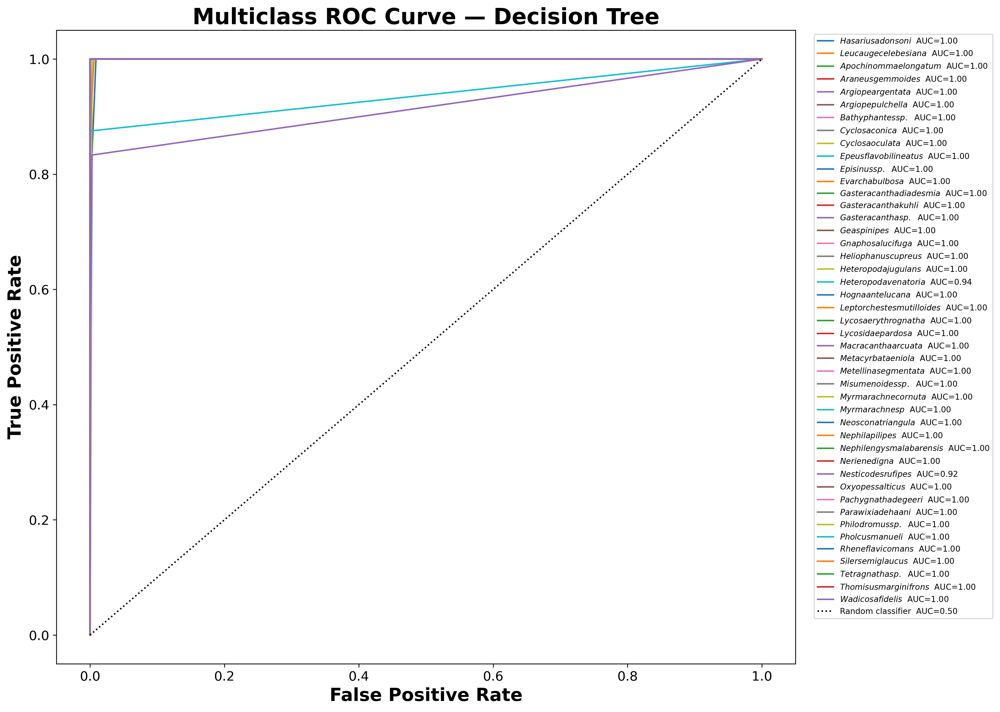

In [26]:
# ============================================================
# CELL 20 — SPECIES-LEVEL ROC: DECISION TREE
# SPECIES NAMES = BOLD + ITALIC
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

model = dt_grid.best_estimator_
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(14, 10), dpi=300)

handles = []
labels = []

for i, species in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    line, = plt.plot(
        fpr,
        tpr,
        linewidth=1.5
    )

    handles.append(line)
    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Random classifier
random_line, = plt.plot(
    [0, 1],
    [0, 1],
    "k:",
    linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.50")

plt.xlabel(
    "False Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "True Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "Multiclass ROC Curve — Decision Tree",
    fontsize=22,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_Decision_Tree_Species.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_Decision_Tree_Species.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

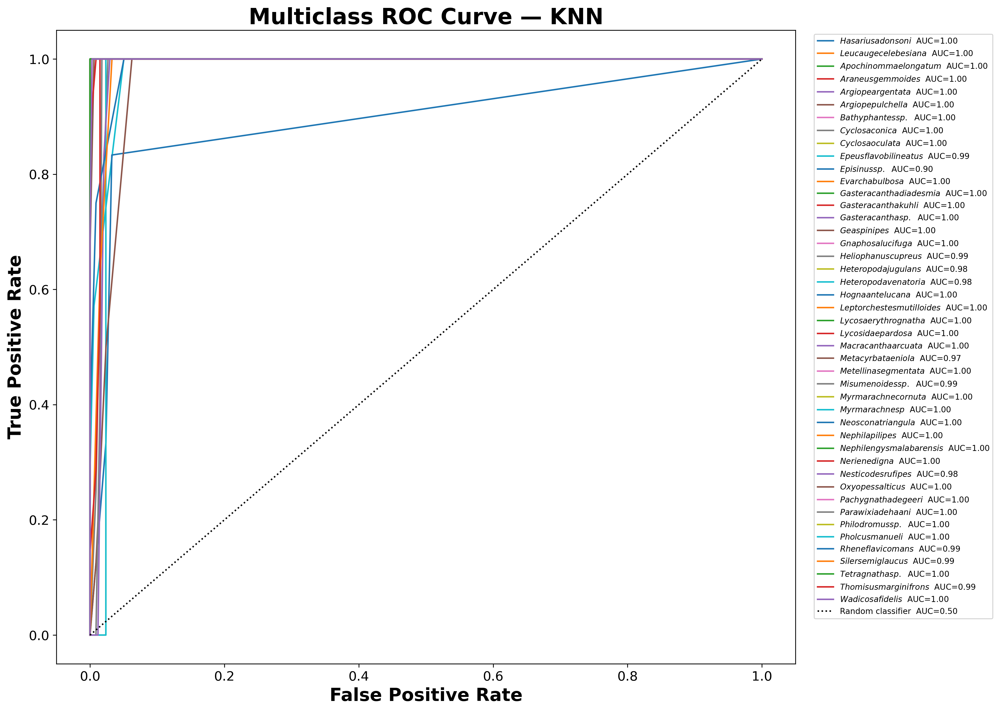

In [27]:
# ============================================================
# CELL 21 — SPECIES-LEVEL ROC: KNN
# ============================================================

model = knn_model
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(14, 10), dpi=300)

handles = []
labels = []

for i, species in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    line, = plt.plot(
        fpr,
        tpr,
        linewidth=1.5
    )

    handles.append(line)
    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Random classifier
random_line, = plt.plot(
    [0, 1],
    [0, 1],
    "k:",
    linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.50")

plt.xlabel(
    "False Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "True Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "Multiclass ROC Curve — KNN",
    fontsize=22,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_KNN_Species.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_KNN_Species.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

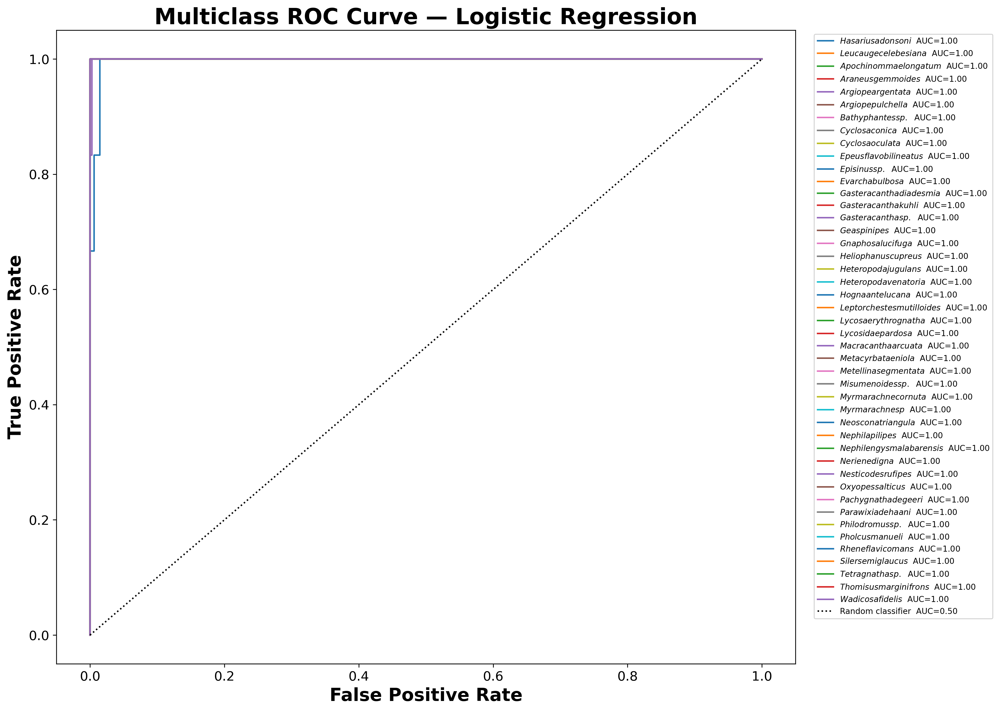

In [28]:
# ============================================================
# CELL 22 — SPECIES-LEVEL ROC: LOGISTIC REGRESSION
# ============================================================

model = lr_model
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(14, 10), dpi=300)

handles = []
labels = []

for i, species in enumerate(classes):

    fpr, tpr, _ = roc_curve(
        y_bin[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    line, = plt.plot(
        fpr,
        tpr,
        linewidth=1.5
    )

    handles.append(line)
    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Random classifier
random_line, = plt.plot(
    [0, 1],
    [0, 1],
    "k:",
    linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.50")

plt.xlabel(
    "False Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "True Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    "Multiclass ROC Curve — Logistic Regression",
    fontsize=22,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_Logistic_Regression_Species.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_Logistic_Regression_Species.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

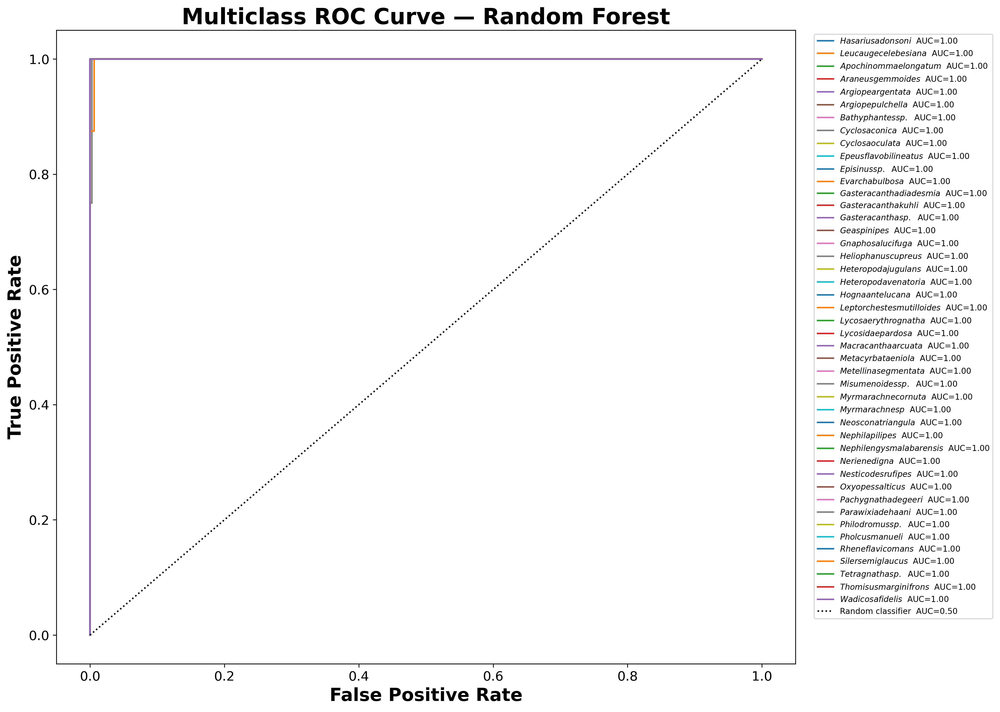

In [29]:
# CELL 23 — SPECIES-LEVEL ROC: RANDOM FOREST

model = rf_model
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(14,10), dpi=300)

handles = []
labels = []

for i, species in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    line, = plt.plot(fpr, tpr, linewidth=1.5)
    handles.append(line)

    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Random classifier
random_line, = plt.plot(
    [0, 1], [0, 1], "k:", linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.50")

plt.xlabel("False Positive Rate", fontsize=18, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=18, fontweight="bold")

plt.title(
    "Multiclass ROC Curve — Random Forest",
    fontsize=22,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_Random_Forest_Species.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_Random_Forest_Species.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

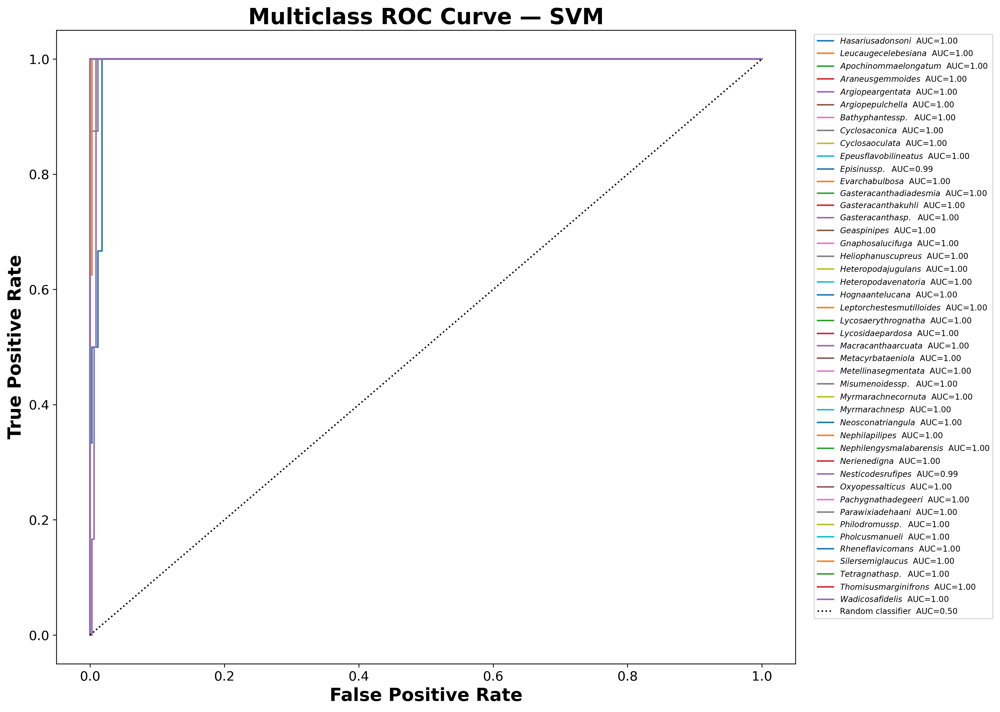

In [30]:
# CELL 24 — SPECIES-LEVEL ROC: SVM

model = svm_model
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(14,10), dpi=300)

handles = []
labels = []

for i, species in enumerate(classes):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    line, = plt.plot(fpr, tpr, linewidth=1.5)
    handles.append(line)

    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Random classifier
random_line, = plt.plot(
    [0, 1], [0, 1], "k:", linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.50")

plt.xlabel("False Positive Rate", fontsize=18, fontweight="bold")
plt.ylabel("True Positive Rate", fontsize=18, fontweight="bold")

plt.title(
    "Multiclass ROC Curve — SVM",
    fontsize=22,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_SVM_Species.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_SVM_Species.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

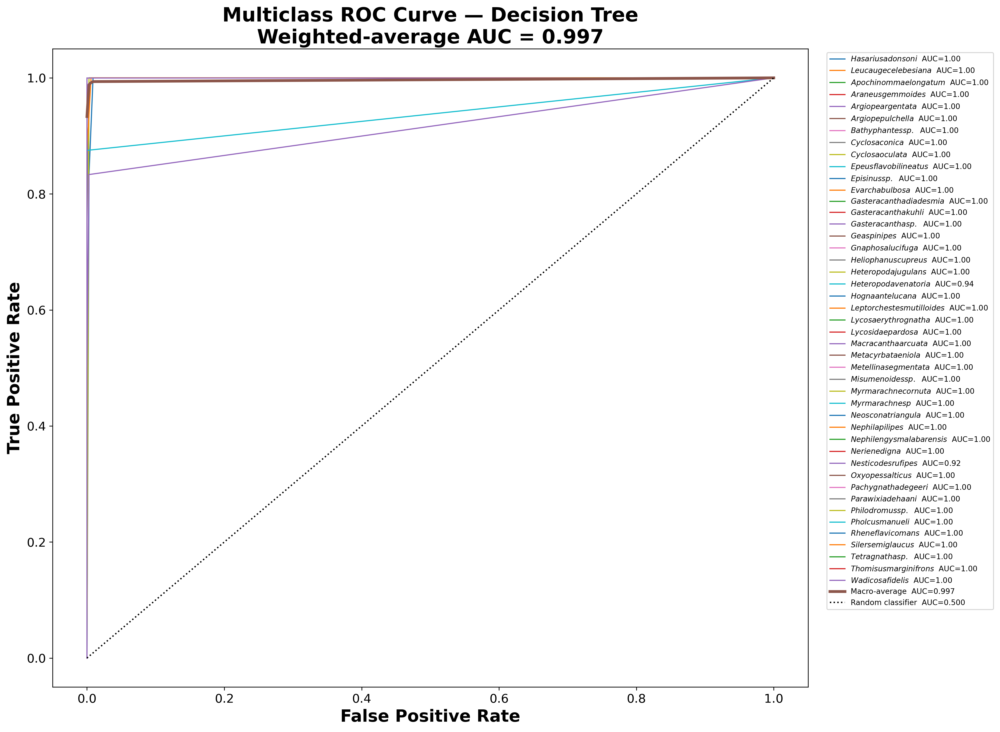

Macro-average AUC    : 0.997
Weighted-average AUC : 0.997


In [31]:
# CELL 25 — DECISION TREE: SPECIES-LEVEL ROC
# Includes Macro-Average AUC + Weighted-Average AUC

from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize
import numpy as np
import matplotlib.pyplot as plt

model = dt_grid.best_estimator_
classes = model.classes_

y_bin = label_binarize(y_test, classes=classes)
y_prob = model.predict_proba(X_test)

plt.figure(figsize=(15,11), dpi=300)

handles = []
labels = []

# Species-level ROC
for i, species in enumerate(classes):

    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)

    line, = plt.plot(fpr, tpr, linewidth=1.2)
    handles.append(line)

    labels.append(
        rf"$\mathbf{{\mathit{{{species}}}}}$  AUC={roc_auc:.2f}"
    )

# Macro-average AUC
macro_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="macro"
)

# Weighted-average AUC
weighted_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

# Macro-average ROC curve
all_fpr = np.unique(
    np.concatenate([
        roc_curve(y_bin[:, i], y_prob[:, i])[0]
        for i in range(len(classes))
    ])
)

mean_tpr = np.zeros_like(all_fpr)

for i in range(len(classes)):
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_prob[:, i])
    mean_tpr += np.interp(all_fpr, fpr, tpr)

mean_tpr /= len(classes)

macro_line, = plt.plot(
    all_fpr,
    mean_tpr,
    linewidth=3,
    linestyle="-"
)

handles.append(macro_line)
labels.append(f"Macro-average  AUC={macro_auc:.3f}")

# Random classifier
random_line, = plt.plot(
    [0, 1],
    [0, 1],
    "k:",
    linewidth=1.5
)

handles.append(random_line)
labels.append("Random classifier  AUC=0.500")

plt.xlabel(
    "False Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.ylabel(
    "True Positive Rate",
    fontsize=18,
    fontweight="bold"
)

plt.title(
    f"Multiclass ROC Curve — Decision Tree\n"
    f"Weighted-average AUC = {weighted_auc:.3f}",
    fontsize=21,
    fontweight="bold"
)

plt.xticks(fontsize=13)
plt.yticks(fontsize=13)

plt.legend(
    handles,
    labels,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    frameon=True
)

plt.tight_layout()

plt.savefig(
    "ROC_Decision_Tree_Species_Macro_Weighted.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "ROC_Decision_Tree_Species_Macro_Weighted.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(f"Macro-average AUC    : {macro_auc:.3f}")
print(f"Weighted-average AUC : {weighted_auc:.3f}")

In [32]:
# CELL 25 — SHAP SETUP FOR ALL MODELS

!pip -q install shap

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

models = {
    "Decision Tree": dt_grid.best_estimator_,
    "KNN": knn_model,
    "Logistic Regression": lr_model,
    "Random Forest": rf_model,
    "SVM": svm_model
}

print("\nModels ready for SHAP:")
for name in models:
    print("✓", name)

SHAP version: 0.52.0

Models ready for SHAP:
✓ Decision Tree
✓ KNN
✓ Logistic Regression
✓ Random Forest
✓ SVM


In [33]:
# CELL 26 — PREPARE TEST DATA FOR SHAP

# Use Decision Tree pipeline to obtain the transformed feature matrix
preprocessor_fitted = dt_grid.best_estimator_.named_steps["preprocessor"]

X_test_transformed = preprocessor_fitted.transform(X_test)

# Get transformed feature names
feature_names = preprocessor_fitted.get_feature_names_out()

# Convert sparse matrix to dense if required
if hasattr(X_test_transformed, "toarray"):
    X_test_shap = X_test_transformed.toarray()
else:
    X_test_shap = X_test_transformed

X_test_shap = pd.DataFrame(
    X_test_shap,
    columns=feature_names,
    index=X_test.index
)

print("SHAP input shape:", X_test_shap.shape)
print("Number of SHAP features:", len(feature_names))
print("Test samples:", len(X_test_shap))

SHAP input shape: (345, 4470)
Number of SHAP features: 4470
Test samples: 345


In [34]:
# CELL 27 — GROUP ONE-HOT FEATURES INTO ORIGINAL PREDICTORS

original_features = X.columns.tolist()

feature_groups = {}

for feature in original_features:
    if feature in numeric_features:
        # Numerical feature has one transformed column
        matches = [
            i for i, name in enumerate(feature_names)
            if name.endswith("__" + feature)
        ]
    else:
        # Categorical feature has multiple one-hot columns
        matches = [
            i for i, name in enumerate(feature_names)
            if name.startswith("cat__" + feature + "_")
        ]

    feature_groups[feature] = matches

print("Original predictors:", len(original_features))
print("Transformed features:", len(feature_names))

print("\nFeature grouping:")
for feature, indices in feature_groups.items():
    print(f"{feature}: {len(indices)} encoded feature(s)")

Original predictors: 36
Transformed features: 4470

Feature grouping:
Body length (mm): 1 encoded feature(s)
Prosoma Length (mm): 1 encoded feature(s)
Prosoma width (mm): 1 encoded feature(s)
Prosoma Shape: 532 encoded feature(s)
Carapace Marking: 654 encoded feature(s)
Abdomen: 5 encoded feature(s)
Abdomen Shape: 550 encoded feature(s)
Abdominal Folium Pattern: 626 encoded feature(s)
Eye Pattern: 418 encoded feature(s)
Anterior Eye Row: 5 encoded feature(s)
Posterior Eye Row: 4 encoded feature(s)
Eye Row Curvature: 8 encoded feature(s)
Eye Spacing: 11 encoded feature(s)
Chelicera Shape: 235 encoded feature(s)
Cheliceral Teeth Count (total per chelicera): 1 encoded feature(s)
Promarginal Teeth Count: 1 encoded feature(s)
Retromarginal Teeth Count: 1 encoded feature(s)
Leg Formula: 7 encoded feature(s)
Leg Spination Density: 16 encoded feature(s)
Femur Spines: 3 encoded feature(s)
Tibia Spines: 3 encoded feature(s)
Metatarsus Spines: 3 encoded feature(s)
Scopula Presence: 4 encoded feat

In [35]:
# CELL 28 — DECISION TREE SHAP VALUES

dt_classifier = dt_grid.best_estimator_.named_steps["classifier"]

explainer_dt = shap.TreeExplainer(dt_classifier)

shap_values_dt = explainer_dt.shap_values(X_test_shap)

print("SHAP calculation completed.")
print("SHAP value type:", type(shap_values_dt))

if isinstance(shap_values_dt, list):
    print("Number of classes:", len(shap_values_dt))
    print("SHAP shape for first class:", shap_values_dt[0].shape)
else:
    print("SHAP shape:", shap_values_dt.shape)

SHAP calculation completed.
SHAP value type: <class 'numpy.ndarray'>
SHAP shape: (345, 4470, 45)


In [36]:
# CELL 29 — AGGREGATE SHAP VALUES TO ORIGINAL FEATURES

# Convert multiclass SHAP values to absolute importance
shap_abs = np.abs(shap_values_dt)

# Average across the 45 species
shap_mean = shap_abs.mean(axis=2)

# Aggregate encoded features belonging to each original predictor
shap_original = pd.DataFrame(index=X_test.index)

for feature, indices in feature_groups.items():
    shap_original[feature] = shap_mean[:, indices].sum(axis=1)

# Mean absolute SHAP importance across test samples
shap_importance = (
    shap_original
    .mean(axis=0)
    .sort_values(ascending=False)
)

print("Original features:", len(shap_importance))
print("\nTop 15 SHAP features:")
print(shap_importance.head(15))

Original features: 36

Top 15 SHAP features:
Leg Formula               0.017831
Eye Spacing               0.013021
Prosoma width (mm)        0.011115
Spinneret Segmentation    0.007368
Abdomen                   0.007250
Spermathecae Shape        0.006508
Body length (mm)          0.005532
Tibia Spines              0.005262
Prosoma Length (mm)       0.004730
Trichobothria Pattern     0.004429
Scopula Presence          0.003586
Copulatory Duct Shape     0.002954
Chelicera Shape           0.001907
Posterior Eye Row         0.001833
Leg Spination Density     0.001700
dtype: float64


Total predictors displayed: 36

SHAP ranking:
Leg Formula                                     0.016864
Eye Spacing                                     0.012695
Prosoma width (mm)                              0.011115
Abdomen                                         0.007250
Spinneret Segmentation                          0.007199
Spermathecae Shape                              0.006221
Body length (mm)                                0.005532
Tibia Spines                                    0.005262
Prosoma Length (mm)                             0.004730
Trichobothria Pattern                           0.004349
Scopula Presence                                0.003526
Copulatory Duct Shape                           0.002954
Chelicera Shape                                 0.001907
Posterior Eye Row                               0.001833
Leg Spination Density                           0.001640
Promarginal Teeth Count                         0.001320
Eye Row Curvature                         

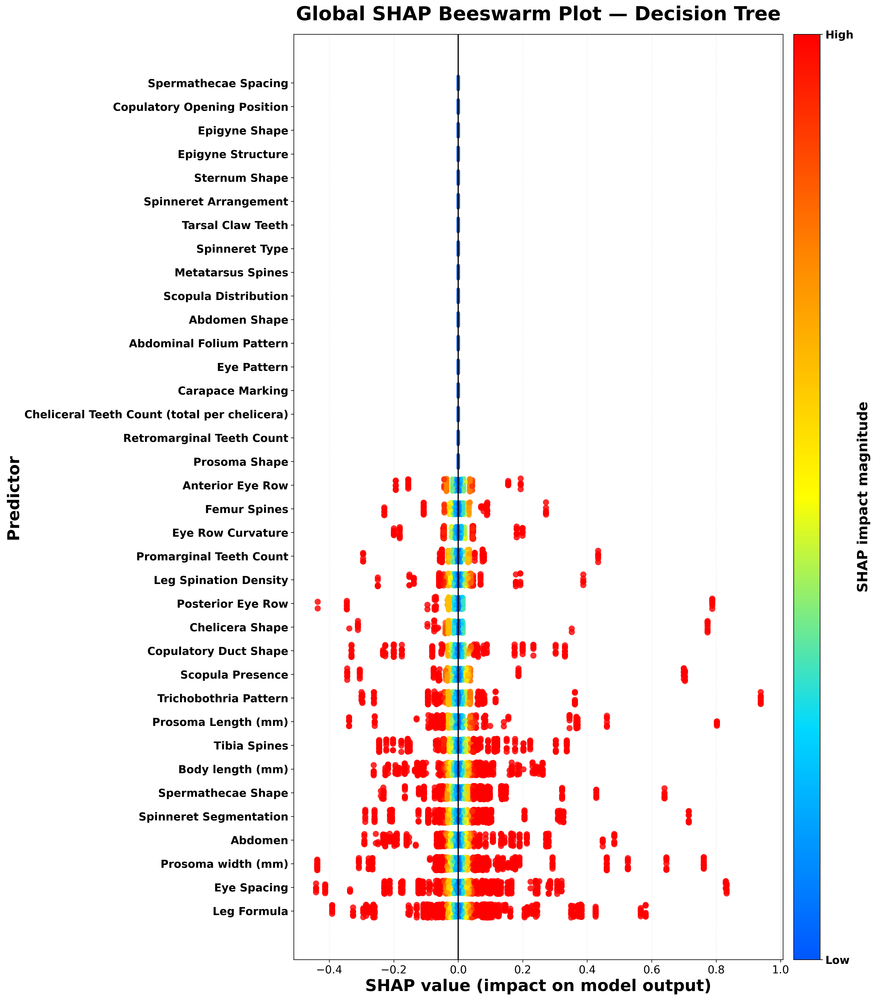

In [37]:
# CELL 30 — GLOBAL SHAP BEESWARM
# All 36 original biological predictors
# Bright colours = high SHAP impact

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize, LinearSegmentedColormap

# ---------------------------------------------------------
# 1. Aggregate SHAP values to original predictors
# ---------------------------------------------------------

global_shap = {}

for feature, indices in feature_groups.items():

    values = shap_values_dt[:, indices, :].sum(axis=1)

    global_shap[feature] = values

# ---------------------------------------------------------
# 2. Calculate global SHAP importance
# ---------------------------------------------------------

importance = {}

for feature in global_shap:

    importance[feature] = np.mean(
        np.abs(global_shap[feature])
    )

importance = pd.Series(
    importance
).sort_values(
    ascending=False
)

top_features = importance.index.tolist()

print("Total predictors displayed:", len(top_features))

print("\nSHAP ranking:")
print(importance)

# ---------------------------------------------------------
# 3. Bright colour map
# ---------------------------------------------------------

bright_cmap = LinearSegmentedColormap.from_list(
    "BrightSHAP",
    [
        "#0057FF",   # bright blue
        "#00D9FF",   # cyan
        "#FFFF00",   # yellow
        "#FF8C00",   # orange
        "#FF0000"    # bright red
    ]
)

# ---------------------------------------------------------
# 4. Determine colour scale
# ---------------------------------------------------------

all_abs = np.concatenate([
    np.abs(global_shap[feature]).ravel()
    for feature in top_features
])

max_impact = np.percentile(
    all_abs,
    99
)

norm = Normalize(
    vmin=0,
    vmax=max_impact
)

# ---------------------------------------------------------
# 5. Create figure
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 18),
    dpi=300
)

np.random.seed(42)

# ---------------------------------------------------------
# 6. Beeswarm points
# ---------------------------------------------------------

for row, feature in enumerate(top_features):

    values = global_shap[feature].ravel()

    impact = np.abs(values)

    colour_values = np.clip(
        impact,
        0,
        max_impact
    )

    # Larger points = stronger SHAP impact
    point_sizes = (
        18 +
        45 * (colour_values / max_impact)
    )

    y = np.full(
        len(values),
        row,
        dtype=float
    )

    y += np.random.uniform(
        -0.28,
        0.28,
        len(values)
    )

    ax.scatter(
        values,
        y,
        c=colour_values,
        cmap=bright_cmap,
        norm=norm,
        s=point_sizes,
        alpha=0.82,
        edgecolors="none"
    )

# ---------------------------------------------------------
# 7. Zero line
# ---------------------------------------------------------

ax.axvline(
    0,
    color="black",
    linewidth=1.5
)

# ---------------------------------------------------------
# 8. Y axis
# ---------------------------------------------------------

ax.set_yticks(
    range(len(top_features))
)

ax.set_yticklabels(
    top_features,
    fontsize=14,
    fontweight="bold"
)

# ---------------------------------------------------------
# 9. Axis labels
# ---------------------------------------------------------

ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=21,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=21,
    fontweight="bold"
)

# ---------------------------------------------------------
# 10. Title
# ---------------------------------------------------------

ax.set_title(
    "Global SHAP Beeswarm Plot — Decision Tree",
    fontsize=25,
    fontweight="bold",
    pad=18
)

ax.tick_params(
    axis="x",
    labelsize=14
)

# ---------------------------------------------------------
# 11. Grid
# ---------------------------------------------------------

ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.8,
    alpha=0.35
)

ax.set_axisbelow(True)

# ---------------------------------------------------------
# 12. Colour bar
# ---------------------------------------------------------

sm = ScalarMappable(
    norm=norm,
    cmap=bright_cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.018,
    aspect=35
)

cbar.set_label(
    "SHAP impact magnitude",
    fontsize=18,
    fontweight="bold"
)

cbar.set_ticks([
    0,
    max_impact
])

cbar.set_ticklabels(
    ["Low", "High"],
    fontsize=14,
    fontweight="bold"
)

# ---------------------------------------------------------
# 13. Save
# ---------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "GLOBAL_SHAP_Beeswarm_Decision_Tree_All_36.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "GLOBAL_SHAP_Beeswarm_Decision_Tree_All_36.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

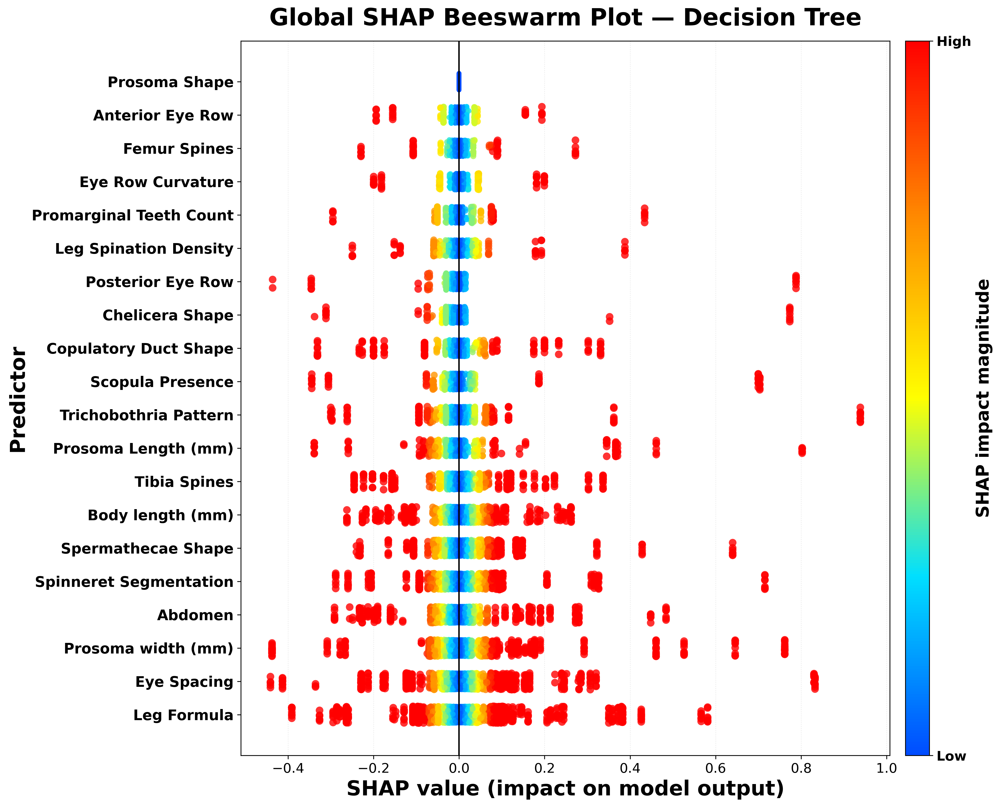

In [38]:
# CELL 31 — FINAL GLOBAL SHAP BEESWARM
# Decision Tree | Top 20 predictors

# Select actual top 20
top_features = importance.head(20).index.tolist()

# Common colour scale
all_abs = np.concatenate([
    np.abs(global_shap[f]).ravel()
    for f in top_features
])

max_impact = np.percentile(all_abs, 99)

norm = Normalize(
    vmin=0,
    vmax=max_impact
)

# Bright colour map
bright_cmap = LinearSegmentedColormap.from_list(
    "BrightSHAP",
    [
        "#004CFF",
        "#00DFFF",
        "#FFFF00",
        "#FF8C00",
        "#FF0000"
    ]
)

fig, ax = plt.subplots(
    figsize=(14, 11),
    dpi=300
)

np.random.seed(42)

for row, feature in enumerate(top_features):

    shap_vals = global_shap[feature].ravel()
    impact = np.abs(shap_vals)

    colour_values = np.clip(
        impact,
        0,
        max_impact
    )

    # Stronger SHAP impact = slightly larger point
    sizes = 20 + 35 * (
        colour_values / max_impact
    )

    y = np.full(
        len(shap_vals),
        row,
        dtype=float
    )

    y += np.random.uniform(
        -0.25,
        0.25,
        len(y)
    )

    ax.scatter(
        shap_vals,
        y,
        c=colour_values,
        cmap=bright_cmap,
        norm=norm,
        s=sizes,
        alpha=0.80,
        edgecolors="none"
    )

# Zero reference
ax.axvline(
    0,
    color="black",
    linewidth=1.4
)

# Predictor labels
ax.set_yticks(range(len(top_features)))

ax.set_yticklabels(
    top_features,
    fontsize=14,
    fontweight="bold"
)

# Labels
ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=20,
    fontweight="bold"
)

ax.set_title(
    "Global SHAP Beeswarm Plot — Decision Tree",
    fontsize=23,
    fontweight="bold",
    pad=15
)

ax.tick_params(
    axis="x",
    labelsize=13
)

# Light grid
ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.7,
    alpha=0.30
)

ax.set_axisbelow(True)

# Colour bar
sm = ScalarMappable(
    norm=norm,
    cmap=bright_cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,
    aspect=30
)

cbar.set_label(
    "SHAP impact magnitude",
    fontsize=17,
    fontweight="bold"
)

cbar.set_ticks([0, max_impact])

cbar.set_ticklabels(
    ["Low", "High"],
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "SHAP_Beeswarm_DT_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "SHAP_Beeswarm_DT_Final.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [39]:
# CELL 32 — KNN SHAP SETUP

from sklearn.pipeline import Pipeline

# ---------------------------------------------------------
# 1. Extract fitted preprocessing and KNN classifier
# ---------------------------------------------------------

knn_preprocessor = knn_model.named_steps["preprocessor"]
knn_classifier = knn_model.named_steps["classifier"]

# Transform training and test data
X_train_knn = knn_preprocessor.transform(X_train)
X_test_knn = knn_preprocessor.transform(X_test)

# Convert sparse matrices to dense
if hasattr(X_train_knn, "toarray"):
    X_train_knn = X_train_knn.toarray()

if hasattr(X_test_knn, "toarray"):
    X_test_knn = X_test_knn.toarray()

# ---------------------------------------------------------
# 2. Background sample
# ---------------------------------------------------------

background_size = min(50, X_train_knn.shape[0])

background_idx = np.random.RandomState(42).choice(
    X_train_knn.shape[0],
    background_size,
    replace=False
)

X_background_knn = X_train_knn[background_idx]

# ---------------------------------------------------------
# 3. Test sample for SHAP
# ---------------------------------------------------------

shap_sample_size = min(100, X_test_knn.shape[0])

X_shap_knn = X_test_knn[:shap_sample_size]

# ---------------------------------------------------------
# 4. Prediction function
# ---------------------------------------------------------

def knn_predict_proba(X):
    return knn_classifier.predict_proba(X)

# ---------------------------------------------------------
# 5. KernelExplainer
# ---------------------------------------------------------

explainer_knn = shap.KernelExplainer(
    knn_predict_proba,
    X_background_knn
)

print("KNN SHAP explainer created.")
print("Background samples:", background_size)
print("SHAP samples:", shap_sample_size)
print("Encoded features:", X_shap_knn.shape[1])
print("Classes:", len(knn_classifier.classes_))

KNN SHAP explainer created.
Background samples: 50
SHAP samples: 100
Encoded features: 4470
Classes: 45


In [40]:
# CELL 33 — RECALCULATE KNN SHAP VALUES
# More stable Kernel SHAP configuration

print("Recalculating KNN SHAP values...")
print("Using regularized feature selection to reduce singularity problems.")

shap_values_knn = explainer_knn.shap_values(
    X_shap_knn,
    nsamples=500,
    l1_reg="num_features(36)"
)

print("\nKNN SHAP calculation completed.")

print(
    "SHAP value type:",
    type(shap_values_knn)
)

if isinstance(shap_values_knn, list):

    print(
        "Number of classes:",
        len(shap_values_knn)
    )

    print(
        "SHAP shape for first class:",
        np.asarray(shap_values_knn[0]).shape
    )

else:

    print(
        "SHAP shape:",
        np.asarray(shap_values_knn).shape
    )

Recalculating KNN SHAP values...
Using regularized feature selection to reduce singularity problems.


  0%|          | 0/100 [00:00<?, ?it/s]


KNN SHAP calculation completed.
SHAP value type: <class 'numpy.ndarray'>
SHAP shape: (100, 4470, 45)


In [41]:
# CELL 34 — KNN SHAP AGGREGATION
# 45 species × 100 samples → 36 original predictors

# SHAP values:
# samples × encoded features × classes

shap_knn_original = {}

for feature, indices in feature_groups.items():

    # Keep every species-specific SHAP contribution
    values = shap_values_knn[:, indices, :].sum(axis=1)

    # Result:
    # 100 samples × 45 species

    shap_knn_original[feature] = values

# ---------------------------------------------------------
# Global SHAP importance
# ---------------------------------------------------------

knn_importance = {}

for feature, values in shap_knn_original.items():

    knn_importance[feature] = np.mean(
        np.abs(values)
    )

knn_importance = pd.Series(
    knn_importance
).sort_values(
    ascending=False
)

print("Original predictors:", len(knn_importance))

print("\nTop 20 KNN SHAP predictors:")
print(knn_importance.head(20))

Original predictors: 36

Top 20 KNN SHAP predictors:
Prosoma Shape                                   0.003489
Abdomen Shape                                   0.003453
Spinneret Type                                  0.003443
Abdominal Folium Pattern                        0.003340
Carapace Marking                                0.003293
Chelicera Shape                                 0.003206
Epigyne Structure                               0.003202
Epigyne Shape                                   0.002982
Eye Pattern                                     0.002970
Spinneret Arrangement                           0.002546
Copulatory Opening Position                     0.002067
Copulatory Duct Shape                           0.002049
Spermathecae Shape                              0.001877
Sternum Shape                                   0.001782
Eye Spacing                                     0.001664
Body length (mm)                                0.001588
Cheliceral Teeth Count (total per c

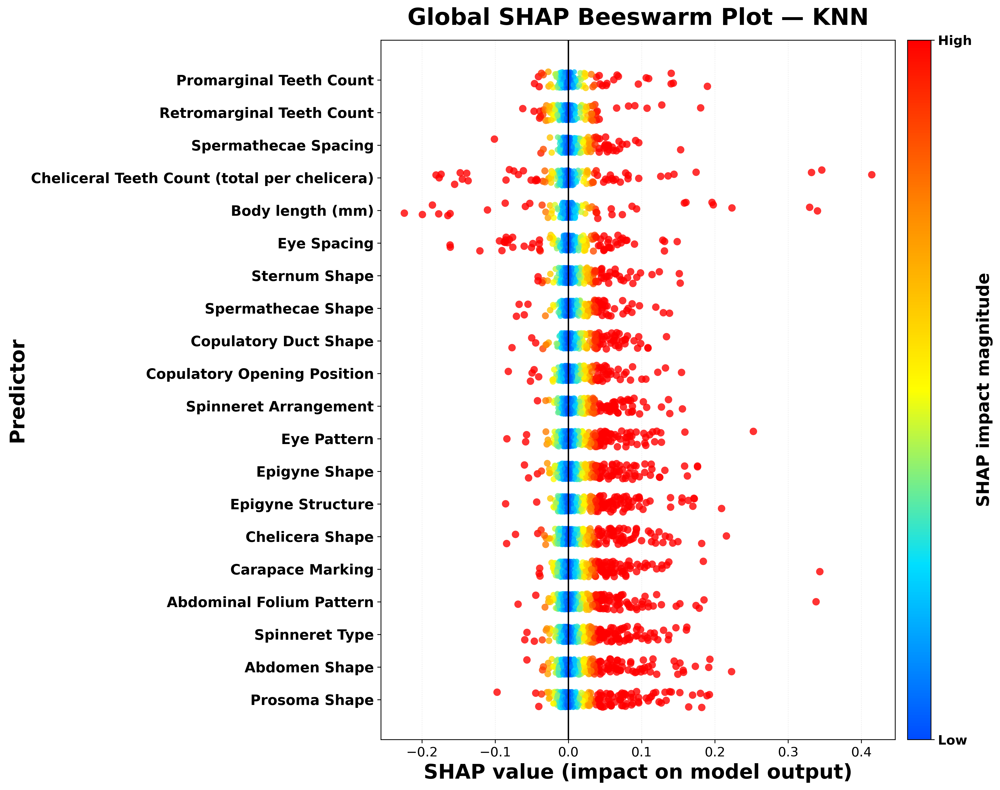

In [42]:
# CELL 35 — GLOBAL KNN SHAP BEESWARM
# Top 20 original biological predictors
# Bright colours = high SHAP impact

# ---------------------------------------------------------
# 1. Select top 20 predictors
# ---------------------------------------------------------

top_features_knn = knn_importance.head(20).index.tolist()

# ---------------------------------------------------------
# 2. Bright colour map
# ---------------------------------------------------------

bright_cmap = LinearSegmentedColormap.from_list(
    "BrightSHAP_KNN",
    [
        "#004CFF",   # blue
        "#00DFFF",   # cyan
        "#FFFF00",   # yellow
        "#FF8C00",   # orange
        "#FF0000"    # red
    ]
)

# ---------------------------------------------------------
# 3. Common SHAP impact scale
# ---------------------------------------------------------

all_abs_knn = np.concatenate([
    np.abs(shap_knn_original[f]).ravel()
    for f in top_features_knn
])

max_impact_knn = np.percentile(
    all_abs_knn,
    99
)

norm_knn = Normalize(
    vmin=0,
    vmax=max_impact_knn
)

# ---------------------------------------------------------
# 4. Create figure
# ---------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 11),
    dpi=300
)

np.random.seed(42)

# ---------------------------------------------------------
# 5. Beeswarm
# ---------------------------------------------------------

for row, feature in enumerate(top_features_knn):

    shap_vals = shap_knn_original[feature].ravel()

    impact = np.abs(shap_vals)

    colour_values = np.clip(
        impact,
        0,
        max_impact_knn
    )

    # Larger points for stronger impact
    sizes = (
        20 +
        35 * (colour_values / max_impact_knn)
    )

    # Vertical jitter
    y = np.full(
        len(shap_vals),
        row,
        dtype=float
    )

    y += np.random.uniform(
        -0.25,
        0.25,
        len(y)
    )

    ax.scatter(
        shap_vals,
        y,
        c=colour_values,
        cmap=bright_cmap,
        norm=norm_knn,
        s=sizes,
        alpha=0.80,
        edgecolors="none"
    )

# ---------------------------------------------------------
# 6. Zero reference
# ---------------------------------------------------------

ax.axvline(
    0,
    color="black",
    linewidth=1.4
)

# ---------------------------------------------------------
# 7. Y axis
# ---------------------------------------------------------

ax.set_yticks(
    range(len(top_features_knn))
)

ax.set_yticklabels(
    top_features_knn,
    fontsize=14,
    fontweight="bold"
)

# ---------------------------------------------------------
# 8. Axis labels
# ---------------------------------------------------------

ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=20,
    fontweight="bold"
)

# ---------------------------------------------------------
# 9. Title
# ---------------------------------------------------------

ax.set_title(
    "Global SHAP Beeswarm Plot — KNN",
    fontsize=23,
    fontweight="bold",
    pad=15
)

ax.tick_params(
    axis="x",
    labelsize=13
)

# ---------------------------------------------------------
# 10. Grid
# ---------------------------------------------------------

ax.grid(
    axis="x",
    linestyle=":",
    linewidth=0.7,
    alpha=0.30
)

ax.set_axisbelow(True)

# ---------------------------------------------------------
# 11. Colour bar
# ---------------------------------------------------------

sm = ScalarMappable(
    norm=norm_knn,
    cmap=bright_cmap
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02,
    aspect=30
)

cbar.set_label(
    "SHAP impact magnitude",
    fontsize=17,
    fontweight="bold"
)

cbar.set_ticks([
    0,
    max_impact_knn
])

cbar.set_ticklabels(
    ["Low", "High"],
    fontsize=13,
    fontweight="bold"
)

# ---------------------------------------------------------
# 12. Save
# ---------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "SHAP_Beeswarm_KNN_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "SHAP_Beeswarm_KNN_Final.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [43]:
# ============================================================
# LOGISTIC REGRESSION — SHAP EXPLANATION
# ============================================================

lr_preprocessor = lr_model.named_steps["preprocessor"]
lr_classifier = lr_model.named_steps["classifier"]

# Transform test data
X_train_lr = lr_preprocessor.transform(X_train)
X_test_lr = lr_preprocessor.transform(X_test)

# Convert sparse matrix to dense if required
if hasattr(X_train_lr, "toarray"):
    X_train_lr = X_train_lr.toarray()

if hasattr(X_test_lr, "toarray"):
    X_test_lr = X_test_lr.toarray()

# Background sample
background_size = min(50, X_train_lr.shape[0])

rng = np.random.RandomState(42)
background_idx = rng.choice(
    X_train_lr.shape[0],
    size=background_size,
    replace=False
)

X_background_lr = X_train_lr[background_idx]

# SHAP sample
shap_sample_size = min(100, X_test_lr.shape[0])
X_shap_lr = X_test_lr[:shap_sample_size]

# Prediction function
def lr_predict_proba(X):
    return lr_classifier.predict_proba(X)

# Kernel SHAP
explainer_lr = shap.KernelExplainer(
    lr_predict_proba,
    X_background_lr
)

print("Logistic Regression SHAP explainer created.")
print("Background samples:", background_size)
print("SHAP samples:", shap_sample_size)
print("Encoded features:", X_shap_lr.shape[1])
print("Classes:", len(lr_classifier.classes_))

Logistic Regression SHAP explainer created.
Background samples: 50
SHAP samples: 100
Encoded features: 4470
Classes: 45


In [44]:
# ============================================================
# LOGISTIC REGRESSION — KERNEL SHAP VALUES
# ============================================================

shap_values_lr = explainer_lr.shap_values(
    X_shap_lr,
    nsamples=500,
    l1_reg="num_features(36)"
)

print("Logistic Regression SHAP calculation completed.")
print("SHAP type:", type(shap_values_lr))
print("SHAP shape:", np.array(shap_values_lr).shape)

  0%|          | 0/100 [00:00<?, ?it/s]

Logistic Regression SHAP calculation completed.
SHAP type: <class 'numpy.ndarray'>
SHAP shape: (100, 4470, 45)


In [45]:
# ============================================================
# LOGISTIC REGRESSION — AGGREGATE SHAP TO ORIGINAL PREDICTORS
# ============================================================

shap_lr_original = {}

for feature, indices in feature_groups.items():
    # Sum SHAP contributions of all encoded levels
    values = shap_values_lr[:, indices, :].sum(axis=1)
    shap_lr_original[feature] = values

# Calculate global mean absolute SHAP importance
lr_importance = {
    feature: np.mean(np.abs(values))
    for feature, values in shap_lr_original.items()
}

lr_importance = pd.Series(
    lr_importance
).sort_values(ascending=False)

print("Top 20 Logistic Regression SHAP predictors:")
print(lr_importance.head(20))

Top 20 Logistic Regression SHAP predictors:
Eye Spacing                                     0.003779
Body length (mm)                                0.002845
Spinneret Type                                  0.002715
Abdomen Shape                                   0.002683
Abdominal Folium Pattern                        0.002625
Carapace Marking                                0.002622
Prosoma Shape                                   0.002574
Chelicera Shape                                 0.002512
Prosoma Length (mm)                             0.002488
Eye Pattern                                     0.002394
Epigyne Structure                               0.002386
Epigyne Shape                                   0.002317
Abdomen                                         0.002241
Copulatory Duct Shape                           0.002165
Copulatory Opening Position                     0.002094
Prosoma width (mm)                              0.002032
Spinneret Arrangement                       

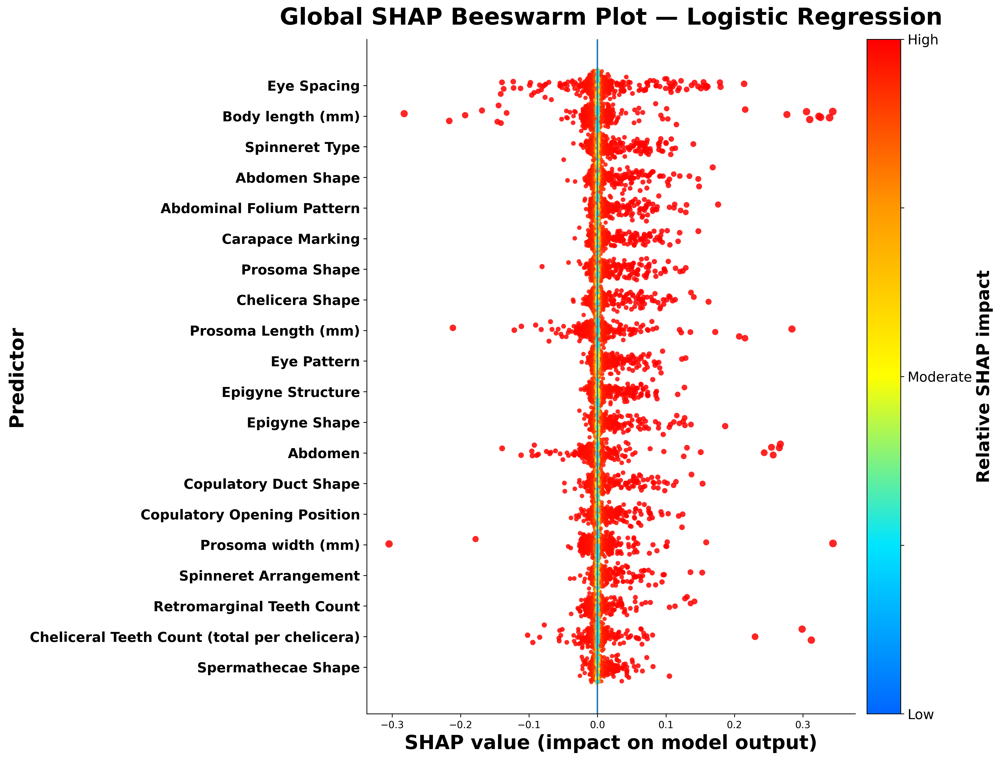

In [48]:
# ============================================================
# LOGISTIC REGRESSION — GLOBAL SHAP IMPACT BEESWARM
# FINAL BALANCED COLOUR DISTRIBUTION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Top 20 predictors
top_features_lr = lr_importance.head(20).index.tolist()

# Bright colour map: Low → High impact
bright_cmap = LinearSegmentedColormap.from_list(
    "bright_impact",
    ["#0066FF", "#00E5FF", "#FFFF00", "#FF9900", "#FF0000"]
)

# ------------------------------------------------------------
# Collect all absolute SHAP impacts
# ------------------------------------------------------------

all_impacts = np.concatenate([
    np.abs(shap_lr_original[f].ravel())
    for f in top_features_lr
])

# Sort impacts for percentile-based colour scaling
sorted_impacts = np.sort(all_impacts)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 11), dpi=300)

for row, feature in enumerate(top_features_lr[::-1]):

    shap_vals = shap_lr_original[feature].ravel()
    impact = np.abs(shap_vals)

    # --------------------------------------------------------
    # Convert impact to percentile rank
    # --------------------------------------------------------

    colour_values = np.searchsorted(
        sorted_impacts,
        impact,
        side="right"
    ) / len(sorted_impacts)

    # --------------------------------------------------------
    # Vertical jitter
    # --------------------------------------------------------

    rng = np.random.RandomState(42 + row)

    y = np.full(len(shap_vals), row, dtype=float)
    y += rng.normal(0, 0.16, len(y))

    # --------------------------------------------------------
    # Point size based on actual relative SHAP impact
    # --------------------------------------------------------

    impact_norm = impact / np.max(all_impacts)

    sizes = 18 + 45 * impact_norm

    # --------------------------------------------------------
    # Scatter
    # --------------------------------------------------------

    ax.scatter(
        shap_vals,
        y,
        c=colour_values,
        cmap=bright_cmap,
        vmin=0,
        vmax=1,
        s=sizes,
        alpha=0.85,
        edgecolors="none"
    )

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(range(20))

ax.set_yticklabels(
    top_features_lr[::-1],
    fontsize=14,
    fontweight="bold"
)

# ------------------------------------------------------------
# Zero reference
# ------------------------------------------------------------

ax.axvline(
    0,
    linewidth=1.5,
    linestyle="-"
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=20,
    fontweight="bold"
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Global SHAP Beeswarm Plot — Logistic Regression",
    fontsize=24,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------

sm = plt.cm.ScalarMappable(
    cmap=bright_cmap,
    norm=plt.Normalize(vmin=0, vmax=1)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Relative SHAP impact",
    fontsize=18,
    fontweight="bold"
)

cbar.set_ticks([0, 0.25, 0.50, 0.75, 1.0])

cbar.set_ticklabels([
    "Low",
    "",
    "Moderate",
    "",
    "High"
])

cbar.ax.tick_params(labelsize=14)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Logistic_Regression_Global_SHAP_Beeswarm_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Logistic_Regression_Global_SHAP_Beeswarm_Final.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [49]:
# ============================================================
# RANDOM FOREST — SHAP EXPLAINER
# ============================================================

rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

# Transform data
X_train_rf = rf_preprocessor.transform(X_train)
X_test_rf = rf_preprocessor.transform(X_test)

# Convert sparse matrix to dense if necessary
if hasattr(X_train_rf, "toarray"):
    X_train_rf = X_train_rf.toarray()

if hasattr(X_test_rf, "toarray"):
    X_test_rf = X_test_rf.toarray()

# Background sample
background_size = min(50, X_train_rf.shape[0])

rng = np.random.RandomState(42)

background_idx = rng.choice(
    X_train_rf.shape[0],
    size=background_size,
    replace=False
)

X_background_rf = X_train_rf[background_idx]

# SHAP sample
shap_sample_size = min(100, X_test_rf.shape[0])

X_shap_rf = X_test_rf[:shap_sample_size]

# Tree SHAP explainer
explainer_rf = shap.TreeExplainer(
    rf_classifier
)

print("Random Forest SHAP explainer created.")
print("Background samples:", background_size)
print("SHAP samples:", shap_sample_size)
print("Encoded features:", X_shap_rf.shape[1])
print("Classes:", len(rf_classifier.classes_))

Random Forest SHAP explainer created.
Background samples: 50
SHAP samples: 100
Encoded features: 4470
Classes: 45


In [51]:
# ============================================================
# RANDOM FOREST — TREE SHAP VALUES
# ADDITIVITY CHECK FIX
# ============================================================

shap_values_rf = explainer_rf.shap_values(
    X_shap_rf,
    check_additivity=False
)

print("Random Forest SHAP calculation completed.")
print("SHAP type:", type(shap_values_rf))
print("SHAP shape:", np.array(shap_values_rf).shape)

Random Forest SHAP calculation completed.
SHAP type: <class 'numpy.ndarray'>
SHAP shape: (100, 4470, 45)


In [52]:
# ============================================================
# RANDOM FOREST — AGGREGATE SHAP TO ORIGINAL PREDICTORS
# ============================================================

shap_rf_original = {}

for feature, indices in feature_groups.items():
    # Combine all one-hot encoded levels belonging
    # to the same original predictor
    values = shap_values_rf[:, indices, :].sum(axis=1)
    shap_rf_original[feature] = values

# Global mean absolute SHAP importance
rf_importance = {
    feature: np.mean(np.abs(values))
    for feature, values in shap_rf_original.items()
}

rf_importance = pd.Series(
    rf_importance
).sort_values(ascending=False)

print("Top 20 Random Forest SHAP predictors:")
print(rf_importance.head(20))

Top 20 Random Forest SHAP predictors:
Eye Spacing                    0.006303
Leg Formula                    0.005940
Abdomen                        0.005714
Trichobothria Pattern          0.005668
Leg Spination Density          0.005229
Eye Row Curvature              0.005034
Anterior Eye Row               0.004783
Spinneret Segmentation         0.004370
Tibia Spines                   0.004143
Femur Spines                   0.004084
Metatarsus Spines              0.003993
Body length (mm)               0.002590
Spermathecae Shape             0.002570
Copulatory Opening Position    0.002344
Prosoma Length (mm)            0.002263
Copulatory Duct Shape          0.002238
Prosoma width (mm)             0.002061
Retromarginal Teeth Count      0.001966
Promarginal Teeth Count        0.001849
Tarsal Claw Teeth              0.001760
dtype: float64


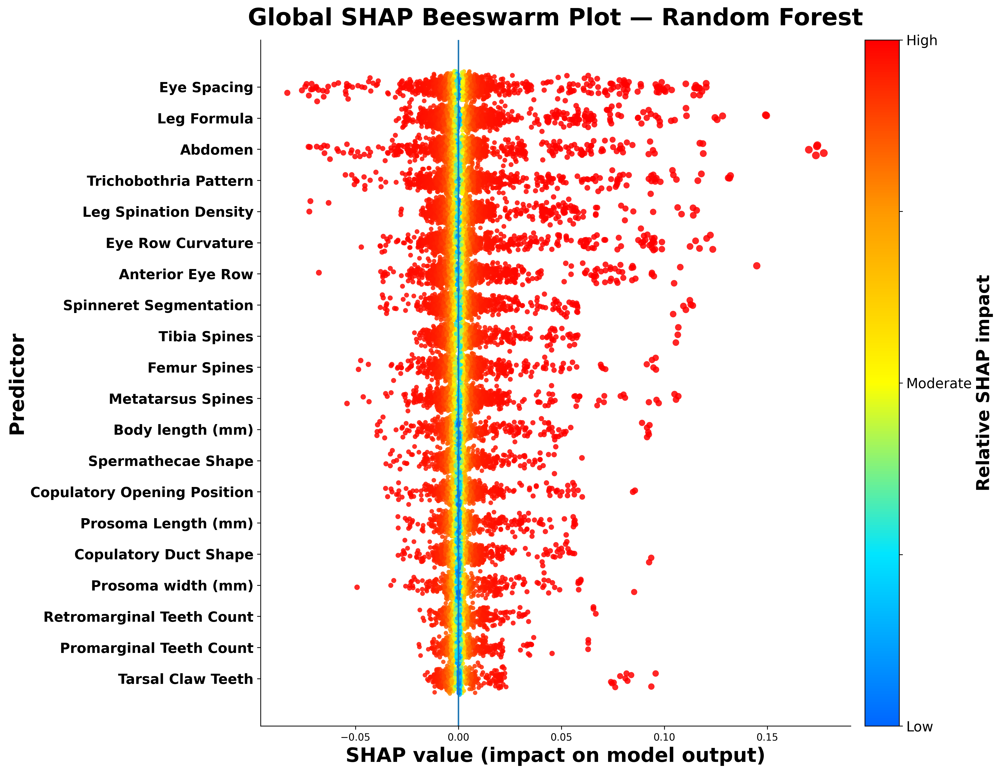

In [53]:
# ============================================================
# RANDOM FOREST — GLOBAL SHAP IMPACT BEESWARM
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# Top 20 predictors
top_features_rf = rf_importance.head(20).index.tolist()

# Bright colour map: Low → High impact
bright_cmap = LinearSegmentedColormap.from_list(
    "bright_impact",
    ["#0066FF", "#00E5FF", "#FFFF00", "#FF9900", "#FF0000"]
)

# ------------------------------------------------------------
# Collect all absolute SHAP impacts
# ------------------------------------------------------------

all_impacts = np.concatenate([
    np.abs(shap_rf_original[f].ravel())
    for f in top_features_rf
])

sorted_impacts = np.sort(all_impacts)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 11), dpi=300)

for row, feature in enumerate(top_features_rf[::-1]):

    shap_vals = shap_rf_original[feature].ravel()
    impact = np.abs(shap_vals)

    # Convert impact to percentile rank
    colour_values = np.searchsorted(
        sorted_impacts,
        impact,
        side="right"
    ) / len(sorted_impacts)

    # Vertical jitter
    rng = np.random.RandomState(42 + row)

    y = np.full(len(shap_vals), row, dtype=float)
    y += rng.normal(0, 0.16, len(y))

    # Point size based on actual SHAP impact
    impact_norm = impact / np.max(all_impacts)

    sizes = 18 + 45 * impact_norm

    ax.scatter(
        shap_vals,
        y,
        c=colour_values,
        cmap=bright_cmap,
        vmin=0,
        vmax=1,
        s=sizes,
        alpha=0.85,
        edgecolors="none"
    )

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(range(20))

ax.set_yticklabels(
    top_features_rf[::-1],
    fontsize=14,
    fontweight="bold"
)

# ------------------------------------------------------------
# Zero reference
# ------------------------------------------------------------

ax.axvline(
    0,
    linewidth=1.5,
    linestyle="-"
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=20,
    fontweight="bold"
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Global SHAP Beeswarm Plot — Random Forest",
    fontsize=24,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------

sm = plt.cm.ScalarMappable(
    cmap=bright_cmap,
    norm=plt.Normalize(vmin=0, vmax=1)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Relative SHAP impact",
    fontsize=18,
    fontweight="bold"
)

cbar.set_ticks([0, 0.25, 0.50, 0.75, 1.0])

cbar.set_ticklabels([
    "Low",
    "",
    "Moderate",
    "",
    "High"
])

cbar.ax.tick_params(labelsize=14)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality files
# ------------------------------------------------------------

plt.savefig(
    "Random_Forest_Global_SHAP_Beeswarm_Final.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Random_Forest_Global_SHAP_Beeswarm_Final.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [54]:
# ============================================================
# SVM — SHAP EXPLAINER
# ============================================================

svm_preprocessor = svm_model.named_steps["preprocessor"]
svm_classifier = svm_model.named_steps["classifier"]

# Transform data
X_train_svm = svm_preprocessor.transform(X_train)
X_test_svm = svm_preprocessor.transform(X_test)

# Convert sparse matrix to dense if necessary
if hasattr(X_train_svm, "toarray"):
    X_train_svm = X_train_svm.toarray()

if hasattr(X_test_svm, "toarray"):
    X_test_svm = X_test_svm.toarray()

# Background sample
background_size = min(50, X_train_svm.shape[0])

rng = np.random.RandomState(42)

background_idx = rng.choice(
    X_train_svm.shape[0],
    size=background_size,
    replace=False
)

X_background_svm = X_train_svm[background_idx]

# SHAP sample
shap_sample_size = min(100, X_test_svm.shape[0])

X_shap_svm = X_test_svm[:shap_sample_size]

# Prediction function
def svm_predict_proba(X):
    return svm_classifier.predict_proba(X)

# Kernel SHAP
explainer_svm = shap.KernelExplainer(
    svm_predict_proba,
    X_background_svm
)

print("SVM SHAP explainer created.")
print("Background samples:", background_size)
print("SHAP samples:", shap_sample_size)
print("Encoded features:", X_shap_svm.shape[1])
print("Classes:", len(svm_classifier.classes_))

SVM SHAP explainer created.
Background samples: 50
SHAP samples: 100
Encoded features: 4470
Classes: 45


In [55]:
# ============================================================
# SVM — KERNEL SHAP VALUES
# ============================================================

shap_values_svm = explainer_svm.shap_values(
    X_shap_svm,
    nsamples=500,
    l1_reg="num_features(36)"
)

print("SVM SHAP calculation completed.")
print("SHAP type:", type(shap_values_svm))
print("SHAP shape:", np.array(shap_values_svm).shape)

  0%|          | 0/100 [00:00<?, ?it/s]

SVM SHAP calculation completed.
SHAP type: <class 'numpy.ndarray'>
SHAP shape: (100, 4470, 45)


In [56]:
# ============================================================
# SVM — AGGREGATE SHAP TO ORIGINAL PREDICTORS
# ============================================================

shap_svm_original = {}

for feature, indices in feature_groups.items():
    # Combine all one-hot encoded levels belonging
    # to the same original predictor
    values = shap_values_svm[:, indices, :].sum(axis=1)
    shap_svm_original[feature] = values

# Global mean absolute SHAP importance
svm_importance = {
    feature: np.mean(np.abs(values))
    for feature, values in shap_svm_original.items()
}

svm_importance = pd.Series(
    svm_importance
).sort_values(ascending=False)

print("Top 20 SVM SHAP predictors:")
print(svm_importance.head(20))

Top 20 SVM SHAP predictors:
Retromarginal Teeth Count                       0.002177
Eye Spacing                                     0.002013
Promarginal Teeth Count                         0.001810
Prosoma Length (mm)                             0.001722
Prosoma width (mm)                              0.001544
Leg Formula                                     0.001350
Eye Row Curvature                               0.001335
Cheliceral Teeth Count (total per chelicera)    0.001269
Body length (mm)                                0.001254
Abdomen                                         0.001227
Abdomen Shape                                   0.001176
Leg Spination Density                           0.001157
Prosoma Shape                                   0.001145
Trichobothria Pattern                           0.001126
Abdominal Folium Pattern                        0.001106
Carapace Marking                                0.001099
Eye Pattern                                     0.001084
Che

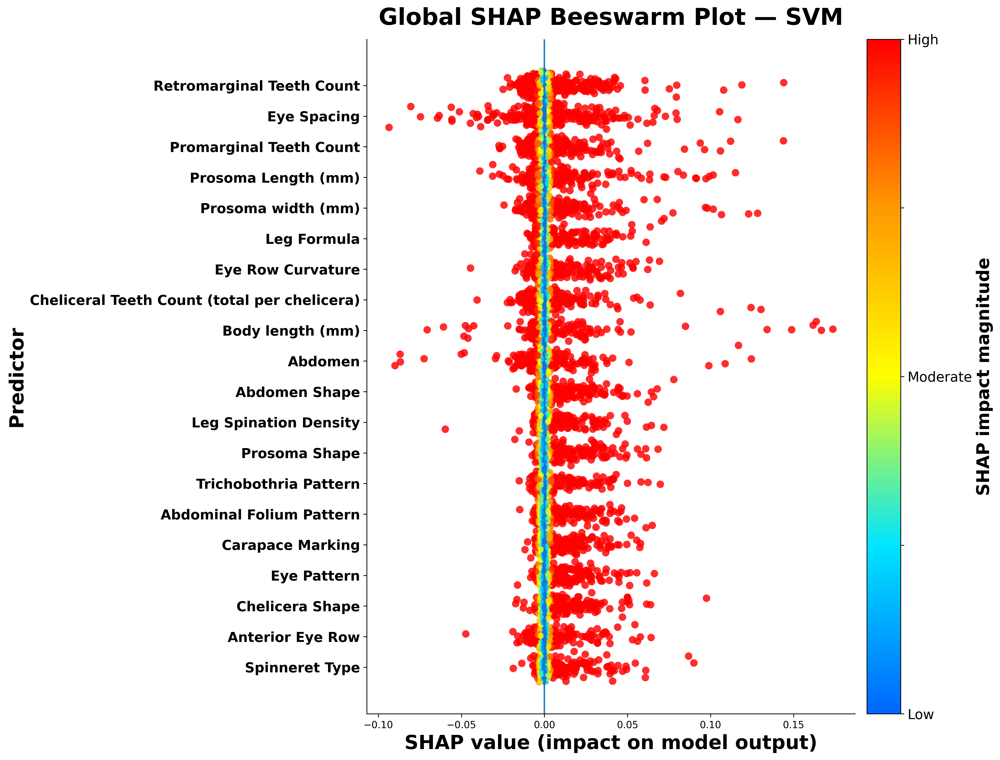

In [64]:
# ============================================================
# SVM — GLOBAL SHAP BEESWARM
# BALANCED COLOUR: BLUE → CYAN → YELLOW → ORANGE → RED
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

# ------------------------------------------------------------
# TOP 20 ORIGINAL PREDICTORS
# ------------------------------------------------------------

top_features_svm = svm_importance.head(20).index.tolist()

# ------------------------------------------------------------
# BRIGHT COLOUR GRADIENT
# ------------------------------------------------------------

bright_cmap = LinearSegmentedColormap.from_list(
    "bright_shap",
    [
        "#0066FF",   # Blue = low
        "#00E5FF",   # Cyan
        "#FFFF00",   # Yellow
        "#FF9900",   # Orange
        "#FF0000"    # Red = high
    ]
)

# ------------------------------------------------------------
# COLLECT SHAP IMPACT
# ------------------------------------------------------------

all_impacts = np.concatenate([
    np.abs(shap_svm_original[feature].ravel())
    for feature in top_features_svm
])

# ------------------------------------------------------------
# ROBUST COLOUR LIMIT
# 95th percentile gives some red without making everything red
# ------------------------------------------------------------

vmax = np.percentile(all_impacts, 95)

if vmax <= 0:
    vmax = np.max(all_impacts)

# ------------------------------------------------------------
# FIGURE
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(14, 11),
    dpi=300
)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

for row, feature in enumerate(top_features_svm[::-1]):

    shap_vals = shap_svm_original[feature].ravel()

    impact = np.abs(shap_vals)

    # Limit colour values only
    # (SHAP values themselves remain unchanged)
    colour_values = np.clip(
        impact,
        0,
        vmax
    )

    # Normalized impact for point size
    impact_norm = np.clip(
        impact / vmax,
        0,
        1
    )

    sizes = 18 + 42 * impact_norm

    # Vertical jitter
    rng = np.random.RandomState(42 + row)

    y = np.full(
        len(shap_vals),
        row,
        dtype=float
    )

    y += rng.normal(
        0,
        0.16,
        len(y)
    )

    ax.scatter(
        shap_vals,
        y,
        c=colour_values,
        cmap=bright_cmap,
        vmin=0,
        vmax=vmax,
        s=sizes,
        alpha=0.82,
        edgecolors="none"
    )

# ------------------------------------------------------------
# Y-AXIS
# ------------------------------------------------------------

ax.set_yticks(range(20))

ax.set_yticklabels(
    top_features_svm[::-1],
    fontsize=14,
    fontweight="bold"
)

# ------------------------------------------------------------
# ZERO LINE
# ------------------------------------------------------------

ax.axvline(
    0,
    linewidth=1.5,
    linestyle="-"
)

# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

ax.set_xlabel(
    "SHAP value (impact on model output)",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Predictor",
    fontsize=20,
    fontweight="bold"
)

# ------------------------------------------------------------
# TITLE
# ------------------------------------------------------------

ax.set_title(
    "Global SHAP Beeswarm Plot — SVM",
    fontsize=24,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# COLOUR BAR
# ------------------------------------------------------------

sm = plt.cm.ScalarMappable(
    cmap=bright_cmap,
    norm=plt.Normalize(
        vmin=0,
        vmax=vmax
    )
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "SHAP impact magnitude",
    fontsize=18,
    fontweight="bold"
)

cbar.set_ticks([
    0,
    vmax * 0.25,
    vmax * 0.50,
    vmax * 0.75,
    vmax
])

cbar.set_ticklabels([
    "Low",
    "",
    "Moderate",
    "",
    "High"
])

cbar.ax.tick_params(
    labelsize=14
)

# ------------------------------------------------------------
# CLEAN
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

plt.savefig(
    "SVM_Global_SHAP_Beeswarm_Balanced.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "SVM_Global_SHAP_Beeswarm_Balanced.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [65]:
# ============================================================
# SPIDER SPECIES ABUNDANCE ANALYSIS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Species abundance
# ------------------------------------------------------------

species_abundance = (
    df["Species"]
    .value_counts()
    .sort_values(ascending=False)
)

# Total number of records
total_records = species_abundance.sum()

# Relative abundance (%)
relative_abundance = (
    species_abundance / total_records
) * 100

# ------------------------------------------------------------
# Create abundance table
# ------------------------------------------------------------

abundance_table = pd.DataFrame({
    "Species": species_abundance.index,
    "Abundance": species_abundance.values,
    "Relative Abundance (%)": relative_abundance.values
})

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 70)
print("SPIDER SPECIES ABUNDANCE")
print("=" * 70)

print("Total records:", total_records)
print("Number of species:", len(abundance_table))

print("\nSpecies-wise abundance:")
display(
    abundance_table.round({
        "Relative Abundance (%)": 2
    })
)

SPIDER SPECIES ABUNDANCE
Total records: 1721
Number of species: 45

Species-wise abundance:


,Species,Abundance,Relative Abundance (%)
0,Nephila pilipes,66,3.83
1,Bathyphantes sp.,61,3.54
2,Gasteracantha kuhli,51,2.96
3,Gasteracantha diadesmia,51,2.96
4,Wadicosa fidelis,48,2.79
5,Hogna antelucana,47,2.73
6,Lycosa erythrognatha,43,2.50
7,Cyclosa conica,43,2.50
8,Gnaphosa lucifuga,41,2.38
9,Neoscona triangula,41,2.38


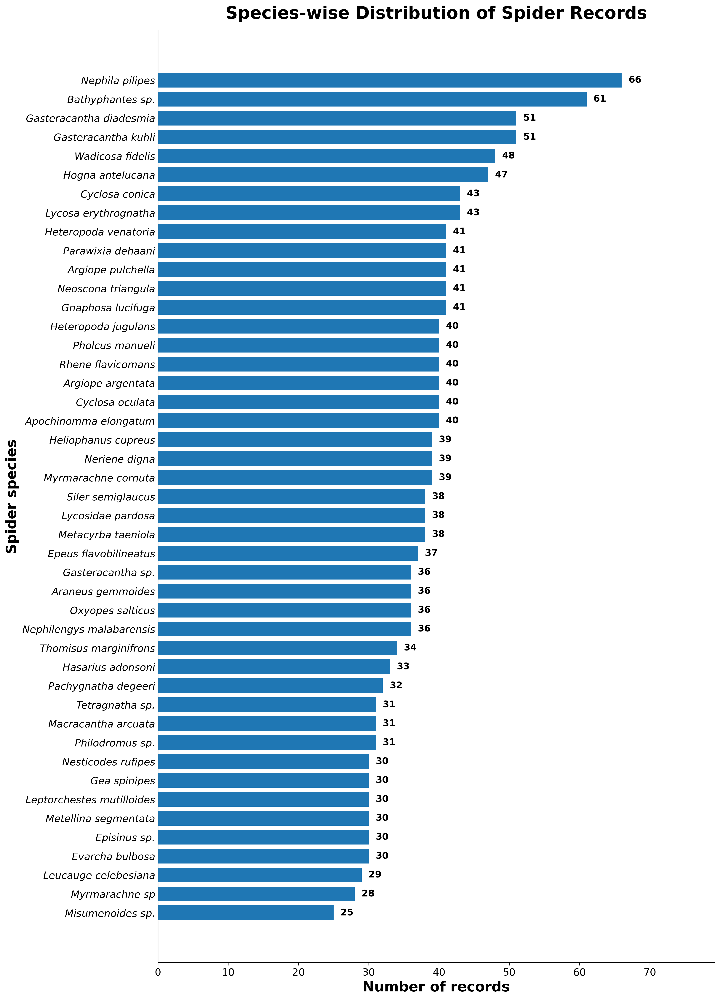

In [66]:
# ============================================================
# SPECIES-WISE DISTRIBUTION OF SPIDER RECORDS
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Sort species from highest to lowest abundance
# ------------------------------------------------------------

plot_data = abundance_table.sort_values(
    "Abundance",
    ascending=True
).copy()

species = plot_data["Species"].tolist()
abundance = plot_data["Abundance"].tolist()

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 18),
    dpi=300
)

y_pos = np.arange(len(species))

bars = ax.barh(
    y_pos,
    abundance,
    height=0.78
)

# ------------------------------------------------------------
# Species names — italic
# ------------------------------------------------------------

ax.set_yticks(y_pos)

ax.set_yticklabels(
    species,
    fontsize=13,
    fontstyle="italic"
)

# ------------------------------------------------------------
# Abundance values at end of bars
# ------------------------------------------------------------

max_abundance = max(abundance)

for bar, value in zip(bars, abundance):

    ax.text(
        bar.get_width() + max_abundance * 0.015,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Number of records",
    fontsize=18,
    fontweight="bold"
)

ax.set_ylabel(
    "Spider species",
    fontsize=18,
    fontweight="bold"
)

ax.set_title(
    "Species-wise Distribution of Spider Records",
    fontsize=22,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# X-axis limit
# ------------------------------------------------------------

ax.set_xlim(
    0,
    max_abundance * 1.20
)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=13
)

ax.tick_params(
    axis="y",
    length=0
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality files
# ------------------------------------------------------------

plt.savefig(
    "Spider_Species_wise_Abundance.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_Species_wise_Abundance.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

GENUS-LEVEL SPECIES RICHNESS OF SPIDER ASSEMBLAGE
Number of genera: 39
Total species: 45


,Genus,Species Richness
0,Gasteracantha,3
1,Cyclosa,2
2,Argiope,2
3,Heteropoda,2
4,Myrmarachne,2
5,Araneus,1
6,Apochinomma,1
7,Episinus,1
8,Epeus,1
9,Bathyphantes,1


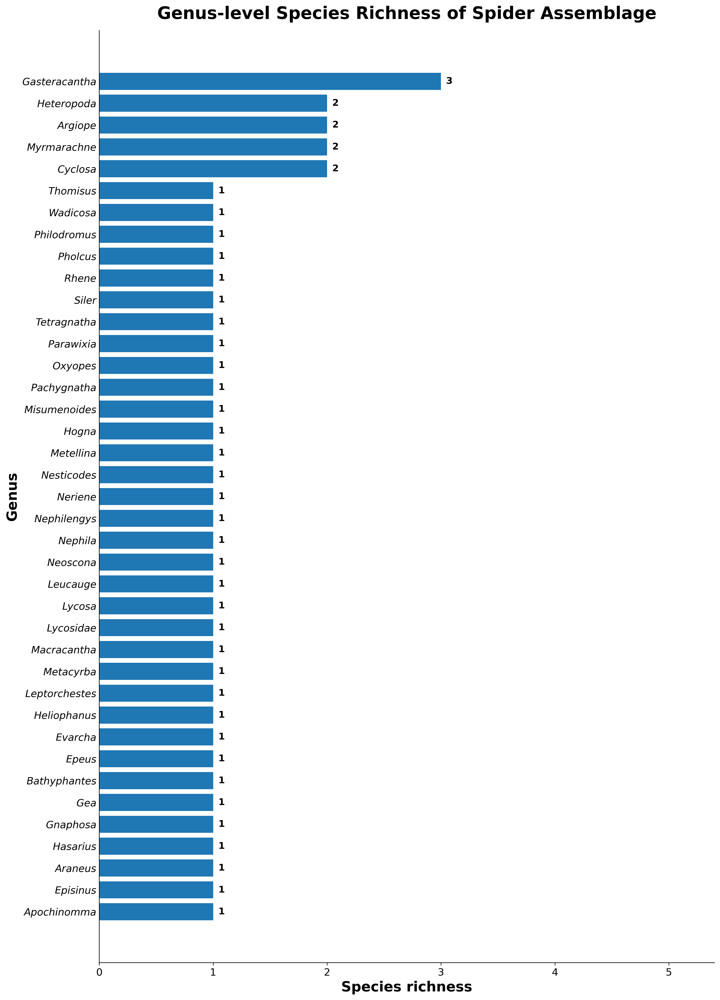

In [67]:
# ============================================================
# GENUS-LEVEL SPECIES RICHNESS OF SPIDER ASSEMBLAGE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Extract genus from species name
# ------------------------------------------------------------

genus_species = (
    df[["Species"]]
    .dropna()
    .copy()
)

genus_species["Genus"] = (
    genus_species["Species"]
    .astype(str)
    .str.strip()
    .str.split()
    .str[0]
)

# ------------------------------------------------------------
# Count unique species within each genus
# ------------------------------------------------------------

genus_richness = (
    genus_species
    .groupby("Genus")["Species"]
    .nunique()
    .sort_values(ascending=False)
)

# ------------------------------------------------------------
# Create table
# ------------------------------------------------------------

genus_richness_table = pd.DataFrame({
    "Genus": genus_richness.index,
    "Species Richness": genus_richness.values
})

print("=" * 70)
print("GENUS-LEVEL SPECIES RICHNESS OF SPIDER ASSEMBLAGE")
print("=" * 70)

print("Number of genera:", len(genus_richness_table))
print(
    "Total species:",
    genus_richness_table["Species Richness"].sum()
)

display(genus_richness_table)

# ------------------------------------------------------------
# Sort for horizontal bar plot
# Highest richness at top
# ------------------------------------------------------------

plot_data = genus_richness_table.sort_values(
    "Species Richness",
    ascending=True
).copy()

genera = plot_data["Genus"].tolist()
richness = plot_data["Species Richness"].tolist()

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(13, 18),
    dpi=300
)

y_pos = np.arange(len(genera))

bars = ax.barh(
    y_pos,
    richness,
    height=0.78
)

# ------------------------------------------------------------
# Genus names — italic
# ------------------------------------------------------------

ax.set_yticks(y_pos)

ax.set_yticklabels(
    genera,
    fontsize=13,
    fontstyle="italic"
)

# ------------------------------------------------------------
# Values at end of bars
# ------------------------------------------------------------

max_richness = max(richness)

for bar, value in zip(bars, richness):

    ax.text(
        bar.get_width() + max_richness * 0.015,
        bar.get_y() + bar.get_height() / 2,
        str(value),
        va="center",
        fontsize=12,
        fontweight="bold"
    )

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Species richness",
    fontsize=18,
    fontweight="bold"
)

ax.set_ylabel(
    "Genus",
    fontsize=18,
    fontweight="bold"
)

ax.set_title(
    "Genus-level Species Richness of Spider Assemblage",
    fontsize=22,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xlim(
    0,
    max_richness + max(1, max_richness * 0.8)
)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=13
)

ax.tick_params(
    axis="y",
    length=0
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Spider_Genus_Level_Species_Richness.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_Genus_Level_Species_Richness.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

Transformed feature matrix: (1721, 4552)
Species profiles: (45, 4552)


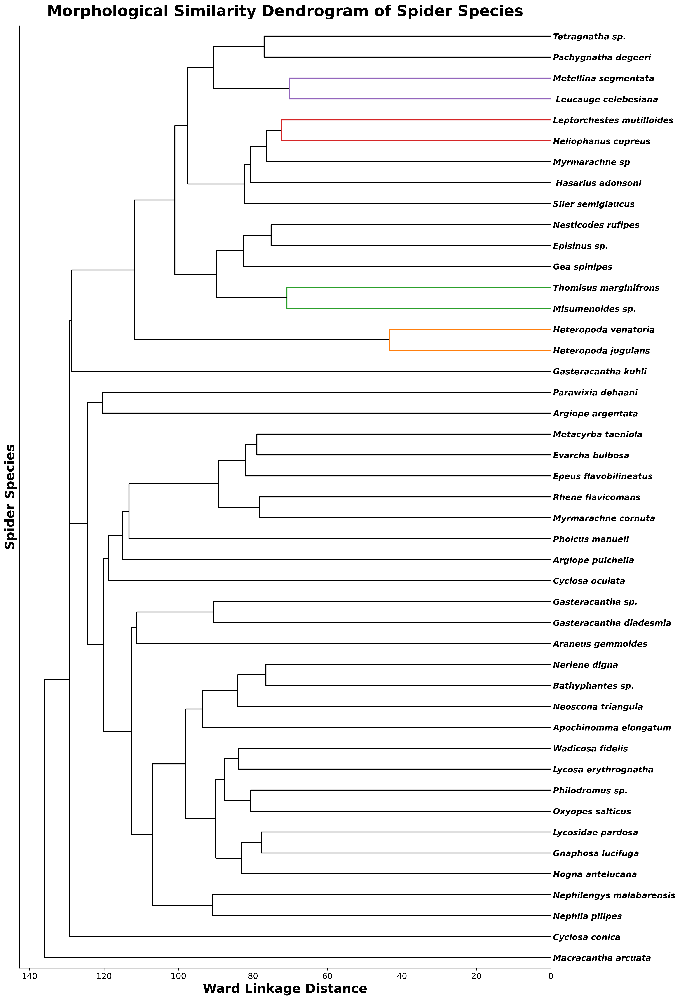


Dendrogram completed successfully.
Number of spider species: 45
Ward maximum distance: 135.921
Colour threshold: 74.757


In [68]:
# ============================================================
# MORPHOLOGICAL SIMILARITY DENDROGRAM OF SPIDER SPECIES
# WARD LINKAGE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# Prepare predictor data
# ------------------------------------------------------------

X_dendro = df.drop(columns=["Species"]).copy()

# ------------------------------------------------------------
# Transform using the same leakage-safe preprocessing
# ------------------------------------------------------------

# Fit preprocessing on the complete dataset for this
# descriptive morphological similarity analysis
X_transformed = preprocessor.fit_transform(X_dendro)

# Convert sparse matrix to dense
if hasattr(X_transformed, "toarray"):
    X_transformed = X_transformed.toarray()

print("Transformed feature matrix:", X_transformed.shape)

# ------------------------------------------------------------
# Species-level morphological profiles
# ------------------------------------------------------------

species_names = df["Species"].values

species_list = sorted(
    df["Species"].dropna().unique()
)

species_profiles = []

for species in species_list:

    mask = species_names == species

    # Mean profile across records belonging to species
    profile = X_transformed[mask].mean(axis=0)

    species_profiles.append(profile)

species_profiles = np.vstack(species_profiles)

print("Species profiles:", species_profiles.shape)

# ------------------------------------------------------------
# Standardize species profiles
# ------------------------------------------------------------

scaler = StandardScaler()

species_profiles_scaled = scaler.fit_transform(
    species_profiles
)

# ------------------------------------------------------------
# Ward hierarchical clustering
# ------------------------------------------------------------

Z = linkage(
    species_profiles_scaled,
    method="ward",
    metric="euclidean"
)

# ------------------------------------------------------------
# Determine colour threshold
# ------------------------------------------------------------

max_distance = Z[:, 2].max()

color_threshold = 0.55 * max_distance

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 22),
    dpi=300
)

dendrogram(
    Z,
    labels=species_list,
    orientation="left",
    color_threshold=color_threshold,
    above_threshold_color="black",
    leaf_font_size=13,
    ax=ax
)

# ------------------------------------------------------------
# Format species names
# ------------------------------------------------------------

for label in ax.get_yticklabels():

    label.set_fontstyle("italic")
    label.set_fontweight("bold")
    label.set_fontsize(13)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Ward Linkage Distance",
    fontsize=20,
    fontweight="bold"
)

ax.set_ylabel(
    "Spider Species",
    fontsize=20,
    fontweight="bold"
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Morphological Similarity Dendrogram of Spider Species",
    fontsize=24,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=13
)

ax.tick_params(
    axis="y",
    length=0
)

plt.tight_layout()

# ------------------------------------------------------------
# Save publication-quality files
# ------------------------------------------------------------

plt.savefig(
    "Spider_Morphological_Similarity_Dendrogram.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_Morphological_Similarity_Dendrogram.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Display clustering information
# ------------------------------------------------------------

print("\nDendrogram completed successfully.")
print("Number of spider species:", len(species_list))
print("Ward maximum distance:", round(max_distance, 3))
print("Colour threshold:", round(color_threshold, 3))

In [70]:
# ============================================================
# RECREATE SHAP IMPORTANCE SERIES FOR ALL FIVE MODELS
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Decision Tree
# ------------------------------------------------------------

dt_importance = pd.Series({
    feature: np.mean(np.abs(shap_values_dt[:, indices, :]))
    for feature, indices in feature_groups.items()
}).sort_values(ascending=False)

# ------------------------------------------------------------
# KNN
# ------------------------------------------------------------

knn_importance = pd.Series({
    feature: np.mean(np.abs(shap_knn_original[feature]))
    for feature in shap_knn_original
}).sort_values(ascending=False)

# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------

lr_importance = pd.Series({
    feature: np.mean(np.abs(shap_lr_original[feature]))
    for feature in shap_lr_original
}).sort_values(ascending=False)

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------

rf_importance = pd.Series({
    feature: np.mean(np.abs(shap_rf_original[feature]))
    for feature in shap_rf_original
}).sort_values(ascending=False)

# ------------------------------------------------------------
# SVM
# ------------------------------------------------------------

svm_importance = pd.Series({
    feature: np.mean(np.abs(shap_svm_original[feature]))
    for feature in shap_svm_original
}).sort_values(ascending=False)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 80)
print("SHAP IMPORTANCE SERIES RECREATED")
print("=" * 80)

print("\nDecision Tree:")
display(dt_importance.head(20))

print("\nKNN:")
display(knn_importance.head(20))

print("\nLogistic Regression:")
display(lr_importance.head(20))

print("\nRandom Forest:")
display(rf_importance.head(20))

print("\nSVM:")
display(svm_importance.head(20))

SHAP IMPORTANCE SERIES RECREATED

Decision Tree:


,0
Prosoma width (mm),0.011115
Body length (mm),0.005532
Prosoma Length (mm),0.004730
Leg Formula,0.002547
Spinneret Segmentation,0.002456
Tibia Spines,0.001754
Abdomen,0.001450
Promarginal Teeth Count,0.001320
Eye Spacing,0.001184
Scopula Presence,0.000896



KNN:


,0
Prosoma Shape,0.003489
Abdomen Shape,0.003453
Spinneret Type,0.003443
Abdominal Folium Pattern,0.003340
Carapace Marking,0.003293
Chelicera Shape,0.003206
Epigyne Structure,0.003202
Epigyne Shape,0.002982
Eye Pattern,0.002970
Spinneret Arrangement,0.002546



Logistic Regression:


,0
Eye Spacing,0.003779
Body length (mm),0.002845
Spinneret Type,0.002715
Abdomen Shape,0.002683
Abdominal Folium Pattern,0.002625
Carapace Marking,0.002622
Prosoma Shape,0.002574
Chelicera Shape,0.002512
Prosoma Length (mm),0.002488
Eye Pattern,0.002394



Random Forest:


,0
Eye Spacing,0.006303
Leg Formula,0.005940
Abdomen,0.005714
Trichobothria Pattern,0.005668
Leg Spination Density,0.005229
Eye Row Curvature,0.005034
Anterior Eye Row,0.004783
Spinneret Segmentation,0.004370
Tibia Spines,0.004143
Femur Spines,0.004084



SVM:


,0
Retromarginal Teeth Count,0.002177
Eye Spacing,0.002013
Promarginal Teeth Count,0.001810
Prosoma Length (mm),0.001722
Prosoma width (mm),0.001544
Leg Formula,0.001350
Eye Row Curvature,0.001335
Cheliceral Teeth Count (total per chelicera),0.001269
Body length (mm),0.001254
Abdomen,0.001227


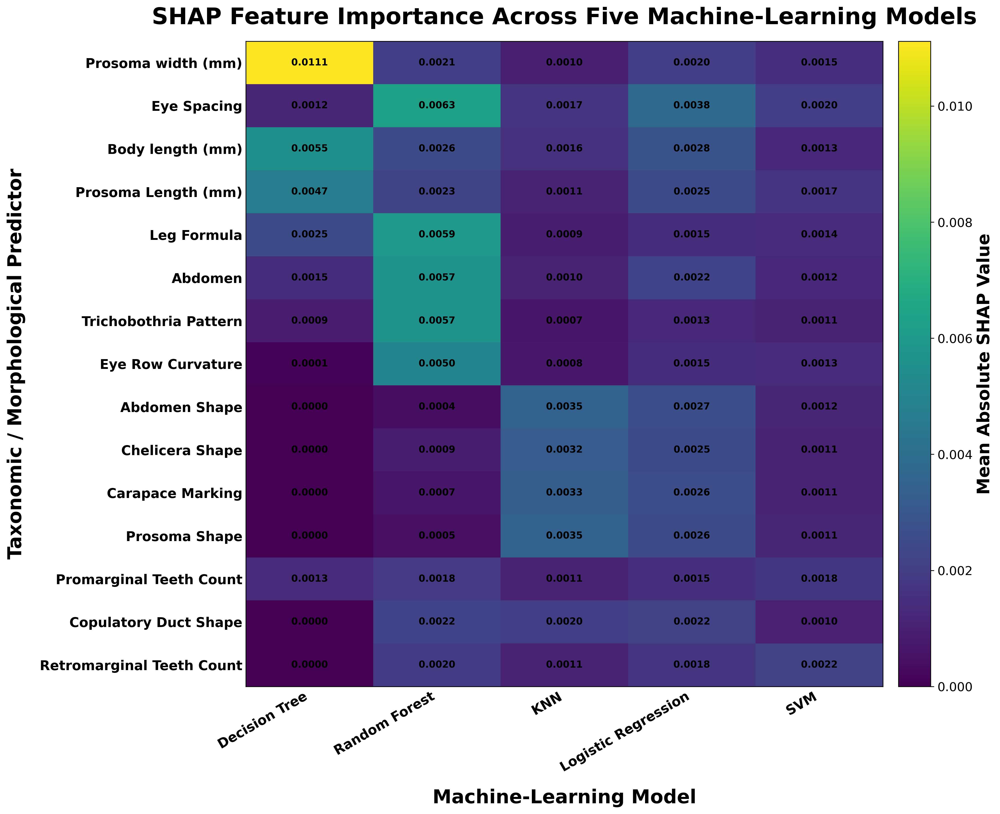

TOP 15 CONSISTENT SHAP PREDICTORS
1. Prosoma width (mm)
2. Eye Spacing
3. Body length (mm)
4. Prosoma Length (mm)
5. Leg Formula
6. Abdomen
7. Trichobothria Pattern
8. Eye Row Curvature
9. Abdomen Shape
10. Chelicera Shape
11. Carapace Marking
12. Prosoma Shape
13. Promarginal Teeth Count
14. Copulatory Duct Shape
15. Retromarginal Teeth Count


In [71]:
# ============================================================
# SHAP FEATURE IMPORTANCE ACROSS FIVE MACHINE-LEARNING MODELS
# SPIDER TAXONOMIC DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Combine all five SHAP importance results
# ------------------------------------------------------------

shap_all = pd.concat(
    [
        dt_importance.rename("Decision Tree"),
        rf_importance.rename("Random Forest"),
        knn_importance.rename("KNN"),
        lr_importance.rename("Logistic Regression"),
        svm_importance.rename("SVM")
    ],
    axis=1
)

# Missing predictors in a model = 0
shap_all = shap_all.fillna(0)

# ------------------------------------------------------------
# Rank predictors within each model
# ------------------------------------------------------------

rank_data = shap_all.rank(
    ascending=False,
    method="average"
)

# Mean rank across five models
rank_data["Mean Rank"] = rank_data.mean(axis=1)

# ------------------------------------------------------------
# Select 15 most consistently important predictors
# ------------------------------------------------------------

top15_features = (
    rank_data
    .sort_values("Mean Rank")
    .head(15)
    .index
)

# ------------------------------------------------------------
# Arrange the selected predictors by overall importance
# ------------------------------------------------------------

shap_top15 = shap_all.loc[
    top15_features,
    [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "Logistic Regression",
        "SVM"
    ]
]

# Highest overall importance at top
shap_top15 = shap_top15.loc[
    shap_top15.mean(axis=1)
    .sort_values(ascending=False)
    .index
]

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 12),
    dpi=300
)

im = ax.imshow(
    shap_top15.values,
    aspect="auto",
    cmap="viridis"
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(5)
)

ax.set_xticklabels(
    [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "Logistic Regression",
        "SVM"
    ],
    fontsize=14,
    fontweight="bold",
    rotation=30,
    ha="right"
)

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(
    np.arange(len(shap_top15))
)

ax.set_yticklabels(
    shap_top15.index,
    fontsize=14,
    fontweight="bold"
)

# ------------------------------------------------------------
# SHAP values inside cells
# ------------------------------------------------------------

for i in range(shap_top15.shape[0]):

    for j in range(shap_top15.shape[1]):

        value = shap_top15.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.4f}",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold"
        )

# ------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "Mean Absolute SHAP Value",
    fontsize=18,
    fontweight="bold"
)

cbar.ax.tick_params(
    labelsize=13
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Machine-Learning Model",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

ax.set_ylabel(
    "Taxonomic / Morphological Predictor",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "SHAP Feature Importance Across Five Machine-Learning Models",
    fontsize=24,
    fontweight="bold",
    pad=18
)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="major",
    length=0
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Spider_SHAP_Feature_Importance_Across_Five_Models.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_SHAP_Feature_Importance_Across_Five_Models.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Print selected predictors
# ------------------------------------------------------------

print("=" * 80)
print("TOP 15 CONSISTENT SHAP PREDICTORS")
print("=" * 80)

for i, feature in enumerate(shap_top15.index, 1):
    print(f"{i}. {feature}")

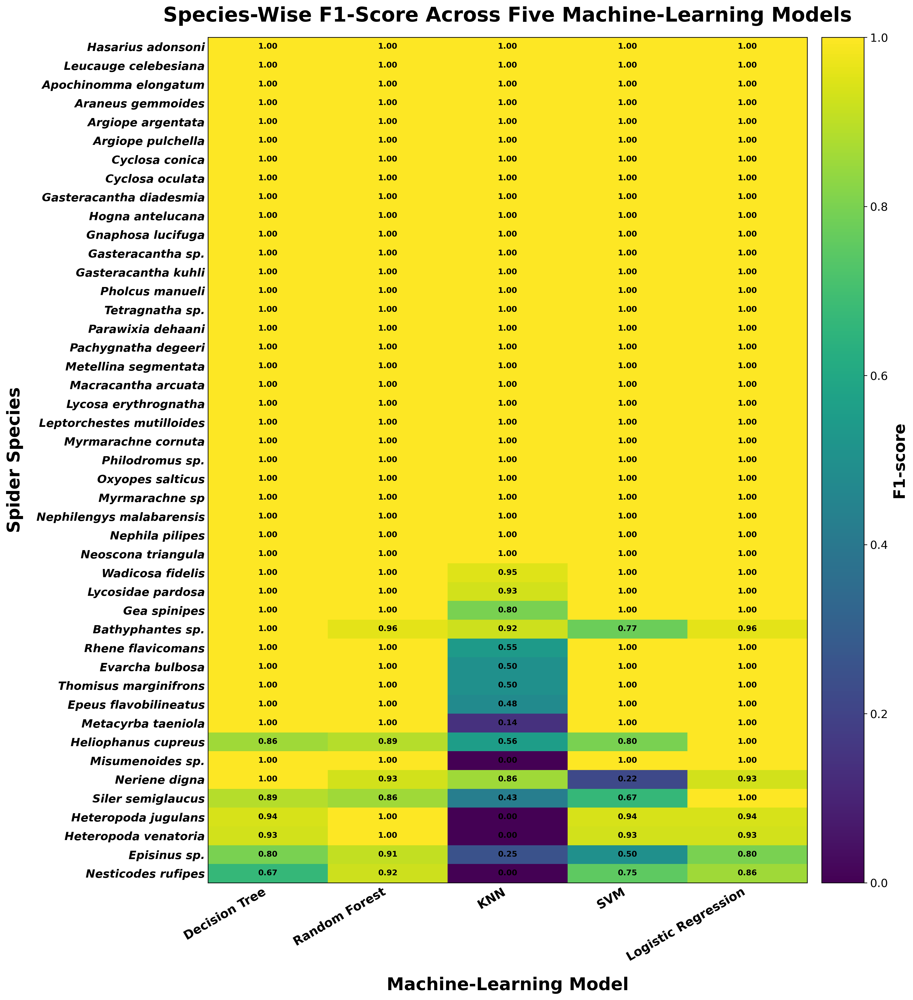

SPECIES-WISE F1-SCORE — ALL FIVE MODELS


,Species,Decision Tree,Random Forest,KNN,SVM,Logistic Regression,Mean F1
0,Hasarius adonsoni,1.000,1.000,1.000,1.000,1.000,1.000
1,Leucauge celebesiana,1.000,1.000,1.000,1.000,1.000,1.000
2,Apochinomma elongatum,1.000,1.000,1.000,1.000,1.000,1.000
3,Araneus gemmoides,1.000,1.000,1.000,1.000,1.000,1.000
4,Argiope argentata,1.000,1.000,1.000,1.000,1.000,1.000
5,Argiope pulchella,1.000,1.000,1.000,1.000,1.000,1.000
6,Cyclosa conica,1.000,1.000,1.000,1.000,1.000,1.000
7,Cyclosa oculata,1.000,1.000,1.000,1.000,1.000,1.000
8,Gasteracantha diadesmia,1.000,1.000,1.000,1.000,1.000,1.000
9,Hogna antelucana,1.000,1.000,1.000,1.000,1.000,1.000


In [72]:
# ============================================================
# SPECIES-WISE F1-SCORE ACROSS FIVE MACHINE-LEARNING MODELS
# SPIDER TAXONOMIC DATASET
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# ------------------------------------------------------------
# All spider species
# ------------------------------------------------------------

species_order = sorted(
    y_test.unique()
)

# ------------------------------------------------------------
# Calculate species-wise F1 scores
# ------------------------------------------------------------

f1_dt = f1_score(
    y_test,
    y_pred_dt,
    labels=species_order,
    average=None,
    zero_division=0
)

f1_knn = f1_score(
    y_test,
    y_pred_knn,
    labels=species_order,
    average=None,
    zero_division=0
)

f1_lr = f1_score(
    y_test,
    y_pred_lr,
    labels=species_order,
    average=None,
    zero_division=0
)

f1_rf = f1_score(
    y_test,
    y_pred_rf,
    labels=species_order,
    average=None,
    zero_division=0
)

f1_svm = f1_score(
    y_test,
    y_pred_svm,
    labels=species_order,
    average=None,
    zero_division=0
)

# ------------------------------------------------------------
# Create F1 dataframe
# ------------------------------------------------------------

f1_table = pd.DataFrame({
    "Species": species_order,
    "Decision Tree": f1_dt,
    "Random Forest": f1_rf,
    "KNN": f1_knn,
    "SVM": f1_svm,
    "Logistic Regression": f1_lr
})

# ------------------------------------------------------------
# Calculate mean F1 across five models
# ------------------------------------------------------------

model_columns = [
    "Decision Tree",
    "Random Forest",
    "KNN",
    "SVM",
    "Logistic Regression"
]

f1_table["Mean F1"] = f1_table[model_columns].mean(axis=1)

# ------------------------------------------------------------
# Sort species by mean F1 — highest at top
# ------------------------------------------------------------

f1_table = f1_table.sort_values(
    "Mean F1",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Matrix for heatmap
# ------------------------------------------------------------

f1_matrix = f1_table[
    [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Logistic Regression"
    ]
].values

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 16),
    dpi=300
)

im = ax.imshow(
    f1_matrix,
    aspect="auto",
    cmap="viridis",
    vmin=0,
    vmax=1
)

# ------------------------------------------------------------
# X-axis
# ------------------------------------------------------------

ax.set_xticks(
    np.arange(5)
)

ax.set_xticklabels(
    [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Logistic Regression"
    ],
    fontsize=14,
    fontweight="bold",
    rotation=30,
    ha="right"
)

# ------------------------------------------------------------
# Y-axis
# ------------------------------------------------------------

ax.set_yticks(
    np.arange(len(f1_table))
)

ax.set_yticklabels(
    f1_table["Species"],
    fontsize=13,
    fontweight="bold",
    fontstyle="italic"
)

# ------------------------------------------------------------
# Add F1 values inside cells
# ------------------------------------------------------------

for i in range(f1_matrix.shape[0]):

    for j in range(f1_matrix.shape[1]):

        value = f1_matrix[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

# ------------------------------------------------------------
# Colour bar
# ------------------------------------------------------------

cbar = fig.colorbar(
    im,
    ax=ax,
    pad=0.02
)

cbar.set_label(
    "F1-score",
    fontsize=18,
    fontweight="bold"
)

cbar.ax.tick_params(
    labelsize=13
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    "Machine-Learning Model",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

ax.set_ylabel(
    "Spider Species",
    fontsize=20,
    fontweight="bold",
    labelpad=15
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "Species-Wise F1-Score Across Five Machine-Learning Models",
    fontsize=23,
    fontweight="bold",
    pad=18
)

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    which="major",
    length=0
)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Spider_Species_Wise_F1_All_Models.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_Species_Wise_F1_All_Models.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# Display numerical table
# ------------------------------------------------------------

print("=" * 90)
print("SPECIES-WISE F1-SCORE — ALL FIVE MODELS")
print("=" * 90)

display(
    f1_table[
        [
            "Species",
            "Decision Tree",
            "Random Forest",
            "KNN",
            "SVM",
            "Logistic Regression",
            "Mean F1"
        ]
    ].round(3)
)

PCA input shape: (1721, 4552)
PC1 explains 14.47% of variance
PC2 explains 7.92% of variance
PC1 + PC2 explain 22.39% of total variance


/tmp/ipykernel_1907/1263841683.py:81: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap(


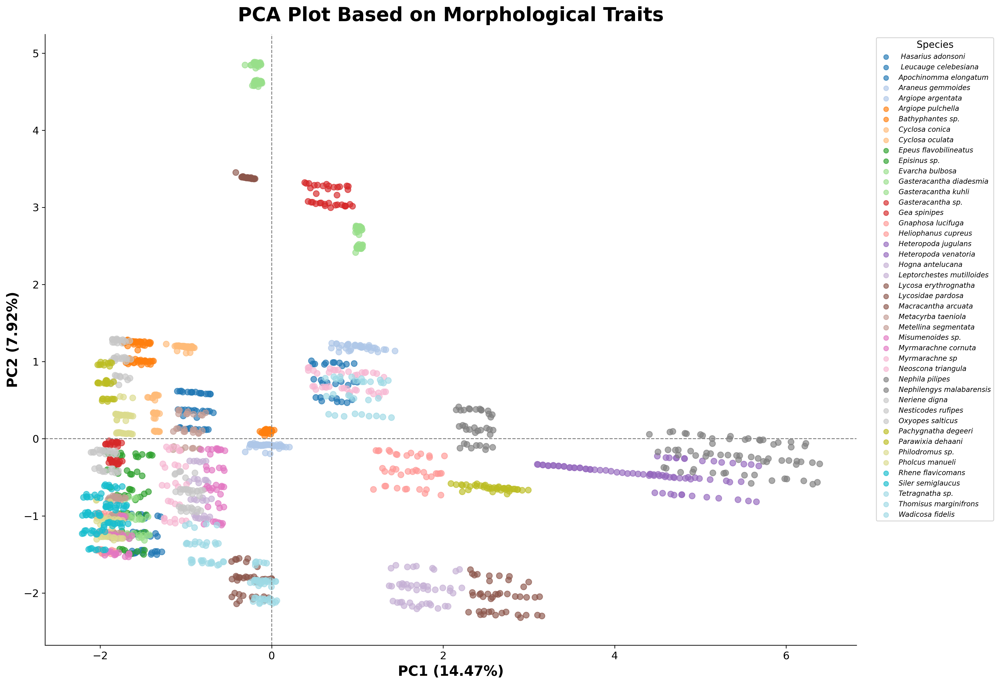

In [73]:
# ============================================================
# PCA PLOT BASED ON MORPHOLOGICAL TRAITS — SPIDERS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

X_pca = df.drop(columns=["Species"]).copy()
y_pca = df["Species"].copy()

# ------------------------------------------------------------
# Preprocess morphological/taxonomic variables
# ------------------------------------------------------------

X_pca_transformed = preprocessor.fit_transform(X_pca)

# Convert sparse matrix to dense
if hasattr(X_pca_transformed, "toarray"):
    X_pca_transformed = X_pca_transformed.toarray()

print("PCA input shape:", X_pca_transformed.shape)

# ------------------------------------------------------------
# PCA
# ------------------------------------------------------------

pca = PCA(
    n_components=2,
    random_state=42
)

X_pca_result = pca.fit_transform(
    X_pca_transformed
)

# Percentage variance explained
pc1_var = pca.explained_variance_ratio_[0] * 100
pc2_var = pca.explained_variance_ratio_[1] * 100

print(f"PC1 explains {pc1_var:.2f}% of variance")
print(f"PC2 explains {pc2_var:.2f}% of variance")
print(
    f"PC1 + PC2 explain "
    f"{pc1_var + pc2_var:.2f}% of total variance"
)

# ------------------------------------------------------------
# Create PCA dataframe
# ------------------------------------------------------------

pca_df = pd.DataFrame({
    "PC1": X_pca_result[:, 0],
    "PC2": X_pca_result[:, 1],
    "Species": y_pca.values
})

# ------------------------------------------------------------
# Species list
# ------------------------------------------------------------

species_list_pca = sorted(
    pca_df["Species"].unique()
)

# ------------------------------------------------------------
# Figure
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(16, 11),
    dpi=300
)

# Use a large categorical colour palette
cmap = plt.cm.get_cmap(
    "tab20",
    len(species_list_pca)
)

# ------------------------------------------------------------
# Plot each species
# ------------------------------------------------------------

for i, species in enumerate(species_list_pca):

    subset = pca_df[
        pca_df["Species"] == species
    ]

    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        s=45,
        alpha=0.65,
        label=species,
        color=cmap(i)
    )

# ------------------------------------------------------------
# Zero reference lines
# ------------------------------------------------------------

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

# ------------------------------------------------------------
# Axis labels
# ------------------------------------------------------------

ax.set_xlabel(
    f"PC1 ({pc1_var:.2f}%)",
    fontsize=16,
    fontweight="bold"
)

ax.set_ylabel(
    f"PC2 ({pc2_var:.2f}%)",
    fontsize=16,
    fontweight="bold"
)

# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "PCA Plot Based on Morphological Traits",
    fontsize=22,
    fontweight="bold",
    pad=15
)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend = ax.legend(
    title="Species",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=8,
    title_fontsize=11,
    frameon=True,
    markerscale=0.8
)

# Italicize species names in legend
for text in legend.get_texts():
    text.set_fontstyle("italic")

# ------------------------------------------------------------
# Clean appearance
# ------------------------------------------------------------

ax.tick_params(
    axis="both",
    labelsize=12
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.savefig(
    "Spider_PCA_Morphological_Traits.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Spider_PCA_Morphological_Traits.pdf",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# COMPLETE MODEL PERFORMANCE METRICS — TEST SET
# Accuracy | Kappa | Sensitivity | Specificity | PPV | NPV
# Balanced Accuracy | F1 | MCC
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    recall_score,
    precision_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    multilabel_confusion_matrix
)

# ------------------------------------------------------------
# Helper: macro specificity and macro NPV for multiclass data
# Each species is evaluated one-vs-rest, then averaged equally.
# ------------------------------------------------------------
def macro_specificity_npv(y_true, y_pred, labels):
    mcm = multilabel_confusion_matrix(
        y_true,
        y_pred,
        labels=labels
    )

    tn = mcm[:, 0, 0].astype(float)
    fp = mcm[:, 0, 1].astype(float)
    fn = mcm[:, 1, 0].astype(float)
    tp = mcm[:, 1, 1].astype(float)

    specificity = np.divide(
        tn, tn + fp,
        out=np.zeros_like(tn, dtype=float),
        where=(tn + fp) != 0
    )

    npv = np.divide(
        tn, tn + fn,
        out=np.zeros_like(tn, dtype=float),
        where=(tn + fn) != 0
    )

    return specificity.mean(), npv.mean()

# ------------------------------------------------------------
# Predictions already produced earlier in this notebook
# ------------------------------------------------------------
test_predictions = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn,
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm
}

labels = np.unique(y_test)

rows = []

for model_name, y_pred in test_predictions.items():

    specificity, npv = macro_specificity_npv(
        y_test,
        y_pred,
        labels
    )

    rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Kappa": cohen_kappa_score(y_test, y_pred),
        "Sensitivity": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Specificity": specificity,
        "PPV": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "NPV": npv,
        "BA": balanced_accuracy_score(y_test, y_pred),
        "F1": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

performance_metrics = pd.DataFrame(rows)

# Keep the same model order as above and round for publication
metric_columns = [
    "Accuracy", "Kappa", "Sensitivity", "Specificity",
    "PPV", "NPV", "BA", "F1", "MCC"
]

performance_metrics[metric_columns] = performance_metrics[metric_columns].round(4)

print("=" * 112)
print("COMPLETE TEST-SET PERFORMANCE METRICS — 45-CLASS SPIDER CLASSIFICATION")
print("=" * 112)
display(performance_metrics)

# Optional percentage version for Accuracy/Sensitivity/etc.
performance_metrics_percent = performance_metrics.copy()
performance_metrics_percent[metric_columns] = (
    performance_metrics_percent[metric_columns] * 100
).round(2)

print("\nSame table expressed as percentages (%):")
display(performance_metrics_percent)

# Save both tables to Excel
with pd.ExcelWriter("Spider_ML_Complete_Performance_Metrics.xlsx") as writer:
    performance_metrics.to_excel(
        writer,
        sheet_name="Metrics_0_to_1",
        index=False
    )
    performance_metrics_percent.to_excel(
        writer,
        sheet_name="Metrics_Percent",
        index=False
    )

print("\nSaved: Spider_ML_Complete_Performance_Metrics.xlsx")
print("\nNOTE: In single-label multiclass classification, macro Sensitivity and")
print("Balanced Accuracy are mathematically the same (mean recall across classes).")


# Additional Random Forest interpretability and species-level error analyses

The following cells reproduce the additional analyses used for the manuscript figures and tables. They are intentionally appended after the main modelling workflow so that they reuse the **same 80:20 stratified train/test split, preprocessing pipeline, and fitted Random Forest model** defined above.

The machine-learning feature analyses use **36 morphological predictors**. `Tarsal Claw Number` is excluded because it is invariant in the dataset. Character names are retained exactly as they appear in the main Excel file.

Additional analyses included here:

1. Random Forest permutation importance
2. Random Forest Mean Decrease Gini (MDI), grouped back to the original morphological characters
3. Random Forest feature importance by grouped minimal depth
4. Boruta-style Random Forest all-relevant feature selection with grouped shadow features
5. Species-level accuracy, error rate, and misclassification summary for all five classifiers

> **Important methodological note:** The Boruta section below is the same custom **Boruta-style** procedure used for the manuscript analysis. It is not a call to the official `Boruta` R package or `BorutaPy`. The grouped implementation is used because one-hot encoding expands a single categorical morphological character into multiple transformed columns.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 1 — VERIFY THE ORIGINAL CHARACTER SET
# ============================================================

from IPython.display import display

expected_ml_characters = [
    "Body length (mm)",
    "Prosoma Length (mm)",
    "Prosoma width (mm)",
    "Prosoma Shape",
    "Carapace Marking",
    "Abdomen",
    "Abdomen Shape",
    "Abdominal Folium Pattern",
    "Eye Pattern",
    "Anterior Eye Row",
    "Posterior Eye Row",
    "Eye Row Curvature",
    "Eye Spacing",
    "Chelicera Shape",
    "Cheliceral Teeth Count (total per chelicera)",
    "Promarginal Teeth Count",
    "Retromarginal Teeth Count",
    "Leg Formula",
    "Leg Spination Density",
    "Femur Spines",
    "Tibia Spines",
    "Metatarsus Spines",
    "Scopula Presence",
    "Scopula Distribution",
    "Trichobothria Pattern",
    "Tarsal Claw Teeth",
    "Spinneret Type",
    "Spinneret Segmentation",
    "Spinneret Arrangement",
    "Sternum Shape",
    "Epigyne Shape",
    "Epigyne Structure",
    "Copulatory Opening Position",
    "Copulatory Duct Shape",
    "Spermathecae Shape",
    "Spermathecae Spacing"
]

actual_ml_characters = X.columns.tolist()

print("Predictors used in ML:", len(actual_ml_characters))
print("Expected predictors:", len(expected_ml_characters))
print("Exact character-name match:", actual_ml_characters == expected_ml_characters)

if set(actual_ml_characters) != set(expected_ml_characters):
    print("\nUnexpected/missing names detected.")
    print("Only in dataset:", sorted(set(actual_ml_characters) - set(expected_ml_characters)))
    print("Only in expected list:", sorted(set(expected_ml_characters) - set(actual_ml_characters)))
else:
    print("\nAll 36 ML character names match the main Excel file exactly.")


In [ ]:
# ============================================================
# RE-FIT A CLEAN RANDOM FOREST FOR THE ADDITIONAL ANALYSES
# ============================================================
#
# Earlier descriptive cells may refit the shared preprocessing object.
# To guarantee that all analyses below use training-only preprocessing,
# construct and fit a fresh Random Forest pipeline here.

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

rf_analysis_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ))
])

rf_analysis_model.fit(X_train, y_train)

rf_analysis_pred = rf_analysis_model.predict(X_test)
rf_analysis_accuracy = accuracy_score(
    y_test,
    rf_analysis_pred
)

print(
    f"Random Forest accuracy used for the additional analyses: "
    f"{rf_analysis_accuracy:.4f} "
    f"({rf_analysis_accuracy*100:.2f}%)"
)

rf_analysis_preprocessor = rf_analysis_model.named_steps[
    "preprocessor"
]
rf_analysis_classifier = rf_analysis_model.named_steps[
    "classifier"
]


## Random Forest permutation importance

Permutation importance measures the decrease in held-out test accuracy after one original morphological character is randomly shuffled. It therefore quantifies how strongly the fitted Random Forest depends on that character for prediction. The analysis is performed on the original 36-column `X_test`, so categorical characters are treated as single biological predictors rather than separate one-hot levels.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 2 — RANDOM FOREST PERMUTATION IMPORTANCE
# ============================================================

from sklearn.inspection import permutation_importance
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

rf_perm = permutation_importance(
    rf_analysis_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy",
    n_jobs=-1
)

rf_permutation_importance = pd.DataFrame({
    "Morphological Character": X_test.columns,
    "Mean Permutation Importance": rf_perm.importances_mean,
    "SD": rf_perm.importances_std
}).sort_values(
    "Mean Permutation Importance",
    ascending=False
).reset_index(drop=True)

print("Random Forest test accuracy:",
      round(accuracy_score(y_test, rf_analysis_pred), 4))

display(rf_permutation_importance)

rf_permutation_importance.to_csv(
    "RF_Permutation_Importance_All_Characters.csv",
    index=False
)

# Publication figure: show only characters with positive mean importance
rf_perm_positive = (
    rf_permutation_importance[
        rf_permutation_importance["Mean Permutation Importance"] > 0
    ]
    .sort_values("Mean Permutation Importance", ascending=True)
)

fig, ax = plt.subplots(figsize=(10.5, 8), dpi=300)

ax.barh(
    rf_perm_positive["Morphological Character"],
    rf_perm_positive["Mean Permutation Importance"],
    xerr=rf_perm_positive["SD"],
    capsize=3
)

ax.set_xlabel(
    "Mean Decrease in Test Accuracy",
    fontsize=16,
    fontweight="bold"
)
ax.set_ylabel(
    "Morphological Character",
    fontsize=16,
    fontweight="bold"
)
ax.set_title(
    "Random Forest Permutation Importance of Morphological Characters",
    fontsize=18,
    fontweight="bold",
    pad=12
)

ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)
for label in ax.get_yticklabels():
    label.set_fontweight("bold")
for label in ax.get_xticklabels():
    label.set_fontweight("bold")

ax.grid(False)
plt.tight_layout()

plt.savefig(
    "RF_Permutation_Importance_Positive_Characters.png",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "RF_Permutation_Importance_Positive_Characters.pdf",
    bbox_inches="tight"
)
plt.show()


## Random Forest Mean Decrease Gini (MDI)

MDI is the Random Forest's impurity-based importance. Because the preprocessing pipeline one-hot encodes categorical characters, encoded-column importances are **summed back to their original morphological character** before ranking. This makes the plot directly interpretable at the biological-character level.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 3 — RANDOM FOREST MDI
# GROUP ONE-HOT COLUMNS BACK TO ORIGINAL CHARACTERS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rf_preprocessor = rf_analysis_preprocessor
rf_classifier = rf_analysis_classifier

# Build a map from each original character to the transformed columns
# used by the fitted Random Forest.
rf_feature_groups = {}
cursor = 0

# Numeric characters contribute one transformed column each.
for feature in numeric_features:
    rf_feature_groups[feature] = [cursor]
    cursor += 1

# Categorical characters contribute one column per one-hot category.
rf_ohe = (
    rf_preprocessor
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

for feature, categories in zip(categorical_features, rf_ohe.categories_):
    n_cols = len(categories)
    rf_feature_groups[feature] = list(
        range(cursor, cursor + n_cols)
    )
    cursor += n_cols

encoded_mdi = rf_classifier.feature_importances_

rf_mdi = pd.DataFrame({
    "Morphological Character": X.columns,
    "Mean Decrease Gini (MDI)": [
        encoded_mdi[rf_feature_groups[feature]].sum()
        for feature in X.columns
    ]
}).sort_values(
    "Mean Decrease Gini (MDI)",
    ascending=False
).reset_index(drop=True)

display(rf_mdi)

rf_mdi.to_csv(
    "RF_Mean_Decrease_Gini_MDI.csv",
    index=False
)

# Matched publication styling
mdi_plot = rf_mdi.sort_values(
    "Mean Decrease Gini (MDI)",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10.5, 12.5), dpi=300)

y_pos = np.arange(len(mdi_plot))

ax.scatter(
    mdi_plot["Mean Decrease Gini (MDI)"],
    y_pos,
    s=150,
    facecolors="red",
    edgecolors="red",
    linewidths=1.0
)

ax.set_yticks(y_pos)
ax.set_yticklabels(
    mdi_plot["Morphological Character"],
    fontsize=12,
    fontweight="bold"
)

ax.set_xlabel(
    "Mean Decrease Gini (MDI)",
    fontsize=16,
    fontweight="bold"
)
ax.set_ylabel(
    "Morphological Character",
    fontsize=16,
    fontweight="bold"
)
ax.set_title(
    "Random Forest Mean Decrease Gini (MDI)\n"
    "Feature Importance of Morphological Characters",
    fontsize=19,
    fontweight="bold",
    pad=14
)

for tick in ax.get_xticklabels():
    tick.set_fontsize(12)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

ax.grid(False)
plt.tight_layout()

plt.savefig(
    "RF_MDI_Same_Font_Axes.png",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "RF_MDI_Same_Font_Axes.pdf",
    bbox_inches="tight"
)
plt.show()


## Random Forest minimal-depth importance

Minimal depth describes how close to the root of a Random Forest tree a character first appears. A lower mean minimal depth indicates that the character tends to participate in earlier, higher-level splits.

The implementation below groups all one-hot columns back to the original morphological character. For every tree, it records the minimum node depth at which any encoded column belonging to that character is used. Characters not used in a tree are recorded as `NA`.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 4 — RANDOM FOREST MINIMAL DEPTH
# GROUPED TO ORIGINAL MORPHOLOGICAL CHARACTERS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

def node_depths_for_tree(tree_):
    """Return the depth of every node in a fitted sklearn tree."""
    n_nodes = tree_.node_count
    depths = np.zeros(n_nodes, dtype=int)

    stack = [(0, 0)]
    while stack:
        node_id, depth = stack.pop()
        depths[node_id] = depth

        left = tree_.children_left[node_id]
        right = tree_.children_right[node_id]

        if left != -1:
            stack.append((left, depth + 1))
        if right != -1:
            stack.append((right, depth + 1))

    return depths


# Reverse map: transformed feature index -> original character
encoded_to_original = {}
for original_feature, indices in rf_feature_groups.items():
    for idx in indices:
        encoded_to_original[idx] = original_feature

minimal_depth_records = []

for tree_number, estimator in enumerate(rf_classifier.estimators_, start=1):
    tree_ = estimator.tree_
    depths = node_depths_for_tree(tree_)

    # Minimum depth observed for each original character in this tree
    per_tree_min = {feature: np.nan for feature in X.columns}

    for node_id, encoded_index in enumerate(tree_.feature):
        if encoded_index < 0:  # leaf
            continue

        original_feature = encoded_to_original.get(encoded_index)
        if original_feature is None:
            continue

        d = int(depths[node_id])

        if np.isnan(per_tree_min[original_feature]) or d < per_tree_min[original_feature]:
            per_tree_min[original_feature] = d

    for feature, depth in per_tree_min.items():
        minimal_depth_records.append({
            "Tree": tree_number,
            "Morphological Character": feature,
            "Minimal Depth": depth
        })

rf_minimal_depth_long = pd.DataFrame(minimal_depth_records)

rf_minimal_depth_summary = (
    rf_minimal_depth_long
    .groupby("Morphological Character", as_index=False)
    .agg(
        Mean_Minimal_Depth=("Minimal Depth", "mean"),
        Median_Minimal_Depth=("Minimal Depth", "median"),
        Trees_Used=("Minimal Depth", "count")
    )
)

rf_minimal_depth_summary["Percent_Trees_Used"] = (
    100
    * rf_minimal_depth_summary["Trees_Used"]
    / len(rf_classifier.estimators_)
)

rf_minimal_depth_summary = rf_minimal_depth_summary.sort_values(
    "Mean_Minimal_Depth",
    ascending=True
).reset_index(drop=True)

display(rf_minimal_depth_summary)

rf_minimal_depth_summary.to_csv(
    "RF_Minimal_Depth_Summary.csv",
    index=False
)
rf_minimal_depth_long.to_csv(
    "RF_Minimal_Depth_By_Tree.csv",
    index=False
)

# ------------------------------------------------------------
# Plot the 15 lowest mean minimal-depth characters
# as distributions of first-use depth across the forest.
# ------------------------------------------------------------
top15_min_depth = rf_minimal_depth_summary.head(15)[
    "Morphological Character"
].tolist()

depth_values = (
    rf_minimal_depth_long["Minimal Depth"]
    .dropna()
    .astype(int)
)

max_depth = int(depth_values.max()) if len(depth_values) else 0
depth_categories = list(range(max_depth + 1)) + ["NA"]

fig, ax = plt.subplots(figsize=(14, 10), dpi=300)

left = np.zeros(len(top15_min_depth))

for depth_category in depth_categories:
    counts = []

    for feature in top15_min_depth:
        subset = rf_minimal_depth_long[
            rf_minimal_depth_long["Morphological Character"] == feature
        ]["Minimal Depth"]

        if depth_category == "NA":
            count = subset.isna().sum()
        else:
            count = (subset == depth_category).sum()

        counts.append(count)

    ax.barh(
        top15_min_depth,
        counts,
        left=left,
        label=str(depth_category)
    )

    left += np.array(counts)

# Put the most important (lowest-depth) character at the top.
ax.invert_yaxis()

# Add the mean minimal-depth value beside each character.
summary_lookup = (
    rf_minimal_depth_summary
    .set_index("Morphological Character")
    ["Mean_Minimal_Depth"]
)

for i, feature in enumerate(top15_min_depth):
    value = summary_lookup.loc[feature]
    ax.text(
        5,
        i,
        f"{value:.2f}",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.2",
            facecolor="white",
            edgecolor="black"
        )
    )

ax.set_xlabel(
    "Number of Trees",
    fontsize=16,
    fontweight="bold"
)
ax.set_ylabel(
    "Morphological Character",
    fontsize=16,
    fontweight="bold"
)
ax.set_title(
    "Random Forest Feature Importance by Minimal Depth",
    fontsize=19,
    fontweight="bold",
    pad=14
)

ax.tick_params(axis="x", labelsize=12)
ax.tick_params(axis="y", labelsize=12)
for label in ax.get_yticklabels():
    label.set_fontweight("bold")
for label in ax.get_xticklabels():
    label.set_fontweight("bold")

ax.grid(False)

ax.legend(
    title="Minimal depth",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=2,
    fontsize=9,
    title_fontsize=10
)

plt.tight_layout()

plt.savefig(
    "Random_Forest_Minimal_Depth_Feature_Importance_Top15.png",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "Random_Forest_Minimal_Depth_Feature_Importance_Top15.pdf",
    bbox_inches="tight"
)
plt.show()


## Boruta-style Random Forest all-relevant feature selection

This grouped Boruta-style procedure tests whether each original morphological character repeatedly exceeds a randomized shadow benchmark.

For each of 50 iterations:

- every original character is copied and independently row-permuted to create a shadow version;
- all one-hot columns belonging to a categorical character are permuted together, preserving that character's encoded block;
- a Random Forest is fitted to the original + shadow predictors;
- one-hot impurity importances are summed back to original-character groups;
- a character receives a **hit** when its grouped importance exceeds the maximum grouped shadow importance.

After 50 iterations, a two-sided decision framework based on one-sided binomial tests (`p = 0.5`) and Bonferroni correction is used to classify characters as Confirmed, Tentative, or Rejected. The figure intentionally omits repeated `Confirmed (50/50)` text to reduce visual clutter.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 5 — BORUTA-STYLE RANDOM FOREST
# GROUPED SHADOW-FEATURE SELECTION
# ============================================================

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier

# Transform the training set with the same fitted preprocessing
# used by the Random Forest.
X_train_rf_transformed = rf_analysis_preprocessor.transform(X_train)

if not sp.issparse(X_train_rf_transformed):
    X_train_rf_transformed = sp.csr_matrix(X_train_rf_transformed)
else:
    X_train_rf_transformed = X_train_rf_transformed.tocsr()

boruta_feature_names = X.columns.tolist()
n_boruta_iterations = 50
n_boruta_trees = 150

boruta_hits = {feature: 0 for feature in boruta_feature_names}
boruta_z_history = {feature: [] for feature in boruta_feature_names}
boruta_shadow_max_z = []

for iteration in range(n_boruta_iterations):

    rng = np.random.RandomState(42 + iteration)

    shadow_blocks = []
    shadow_groups = {}

    shadow_cursor = X_train_rf_transformed.shape[1]

    # Create one grouped shadow copy for every original character.
    for feature in boruta_feature_names:

        original_indices = rf_feature_groups[feature]

        row_permutation = rng.permutation(
            X_train_rf_transformed.shape[0]
        )

        shadow_block = (
            X_train_rf_transformed[:, original_indices]
            [row_permutation, :]
        )

        shadow_groups[feature] = list(
            range(
                shadow_cursor,
                shadow_cursor + shadow_block.shape[1]
            )
        )

        shadow_cursor += shadow_block.shape[1]
        shadow_blocks.append(shadow_block)

    X_augmented = sp.hstack(
        [X_train_rf_transformed] + shadow_blocks,
        format="csr"
    )

    boruta_rf = RandomForestClassifier(
        n_estimators=n_boruta_trees,
        random_state=1000 + iteration,
        n_jobs=-1
    )

    boruta_rf.fit(
        X_augmented,
        y_train
    )

    encoded_importance = boruta_rf.feature_importances_

    original_group_importance = np.array([
        encoded_importance[
            rf_feature_groups[feature]
        ].sum()
        for feature in boruta_feature_names
    ])

    shadow_group_importance = np.array([
        encoded_importance[
            shadow_groups[feature]
        ].sum()
        for feature in boruta_feature_names
    ])

    # Standardized importance is used for the figure.
    all_group_importance = np.concatenate([
        original_group_importance,
        shadow_group_importance
    ])

    mean_imp = all_group_importance.mean()
    sd_imp = all_group_importance.std(ddof=0)

    if sd_imp == 0:
        z_original = np.zeros_like(original_group_importance)
        z_shadow = np.zeros_like(shadow_group_importance)
    else:
        z_original = (
            original_group_importance - mean_imp
        ) / sd_imp

        z_shadow = (
            shadow_group_importance - mean_imp
        ) / sd_imp

    max_shadow_raw = shadow_group_importance.max()
    boruta_shadow_max_z.append(
        z_shadow.max()
    )

    for feature, raw_importance, z_value in zip(
        boruta_feature_names,
        original_group_importance,
        z_original
    ):

        if raw_importance > max_shadow_raw:
            boruta_hits[feature] += 1

        boruta_z_history[feature].append(
            z_value
        )

# ------------------------------------------------------------
# Statistical decision
# ------------------------------------------------------------
alpha = 0.05
bonferroni_alpha = alpha / len(boruta_feature_names)

boruta_rows = []

for feature in boruta_feature_names:

    hits = boruta_hits[feature]

    p_greater = binomtest(
        hits,
        n_boruta_iterations,
        0.5,
        alternative="greater"
    ).pvalue

    p_less = binomtest(
        hits,
        n_boruta_iterations,
        0.5,
        alternative="less"
    ).pvalue

    if p_greater < bonferroni_alpha:
        decision = "Confirmed"
    elif p_less < bonferroni_alpha:
        decision = "Rejected"
    else:
        decision = "Tentative"

    values = np.asarray(
        boruta_z_history[feature]
    )

    boruta_rows.append({
        "Morphological Character": feature,
        "Hits": hits,
        "Iterations": n_boruta_iterations,
        "Hit Rate": hits / n_boruta_iterations,
        "Median Z": np.median(values),
        "Mean Z": np.mean(values),
        "Decision": decision,
        "P_greater": p_greater,
        "P_less": p_less
    })

boruta_results = pd.DataFrame(
    boruta_rows
).sort_values(
    "Median Z",
    ascending=False
).reset_index(drop=True)

display(boruta_results)

print("\nDecision counts:")
display(
    boruta_results["Decision"]
    .value_counts()
    .rename_axis("Decision")
    .reset_index(name="Number of characters")
)

boruta_results.to_csv(
    "Boruta_Style_RF_Morphological_Character_Selection.csv",
    index=False
)

# ------------------------------------------------------------
# Publication figure
# ------------------------------------------------------------
boruta_plot_order = boruta_results[
    "Morphological Character"
].tolist()

boruta_plot_data = [
    np.asarray(
        boruta_z_history[feature]
    )
    for feature in boruta_plot_order
]

median_shadow_max = float(
    np.median(boruta_shadow_max_z)
)

fig, ax = plt.subplots(
    figsize=(10.5, 12.5),
    dpi=300
)

positions = np.arange(
    1,
    len(boruta_plot_order) + 1
)

ax.boxplot(
    boruta_plot_data,
    vert=False,
    positions=positions,
    widths=0.55,
    patch_artist=False,
    showfliers=False,
    medianprops={"linewidth": 2.0},
    whiskerprops={"linewidth": 1.35},
    capprops={"linewidth": 1.35},
    boxprops={"linewidth": 1.35}
)

ax.set_yticks(positions)
ax.set_yticklabels(
    boruta_plot_order,
    fontsize=12,
    fontweight="bold"
)
ax.invert_yaxis()

ax.set_xlabel(
    "Boruta Importance (Standardized Random Forest Importance, Z)",
    fontsize=16,
    fontweight="bold"
)
ax.set_ylabel(
    "Morphological Character",
    fontsize=16,
    fontweight="bold"
)
ax.set_title(
    "Boruta Random Forest Selection of Informative Morphological Characters",
    fontsize=19,
    fontweight="bold",
    pad=14
)

ax.axvline(
    median_shadow_max,
    linestyle="--",
    linewidth=2.0
)

# Vertical annotation positioned slightly inside the plotting region.
ax.text(
    median_shadow_max + 0.13,
    6.2,
    f"Median shadow max = {median_shadow_max:.2f}",
    fontsize=15,
    fontweight="bold",
    rotation=90,
    va="center",
    ha="center",
    bbox={
        "boxstyle": "round,pad=0.25",
        "facecolor": "white",
        "alpha": 0.96,
        "edgecolor": "black",
        "linewidth": 1.0
    }
)

for tick in ax.get_xticklabels():
    tick.set_fontsize(12)
    tick.set_fontweight("bold")

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

ax.grid(False)
plt.tight_layout()

plt.savefig(
    "Boruta_RF_Same_Font_Axes.png",
    dpi=600,
    bbox_inches="tight"
)
plt.savefig(
    "Boruta_RF_Same_Font_Axes.pdf",
    bbox_inches="tight"
)
plt.show()


## Species-level accuracy, error rate, and misclassification summary

The table below calculates performance separately for each **true species**. Species-level accuracy is the proportion of test specimens from that species classified correctly; species-level error is `100 − accuracy`.

Only species with at least one misclassified test specimen are retained in the final table. If a true species is misclassified into more than one predicted species, one row is shown for each incorrect destination and the number of misclassified records is reported.


In [ ]:
# ============================================================
# ADDITIONAL ANALYSIS 6 — SPECIES-LEVEL MISCLASSIFICATION TABLE
# ALL FIVE SUPERVISED ML MODELS
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

model_predictions_for_species_table = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "KNN": y_pred_knn,
    "Logistic Regression": y_pred_lr,
    "SVM": y_pred_svm
}

species_labels = np.unique(y_test)
species_level_rows = []

for model_name, predictions in model_predictions_for_species_table.items():

    cm_counts = confusion_matrix(
        y_test,
        predictions,
        labels=species_labels
    )

    for true_idx, true_species in enumerate(species_labels):

        total_true = cm_counts[
            true_idx, :
        ].sum()

        correct = cm_counts[
            true_idx,
            true_idx
        ]

        if total_true == 0:
            continue

        species_accuracy = (
            100 * correct / total_true
        )

        species_error = (
            100 - species_accuracy
        )

        # Only include species with at least one error.
        if species_error == 0:
            continue

        for pred_idx, predicted_species in enumerate(species_labels):

            if pred_idx == true_idx:
                continue

            n_misclassified = cm_counts[
                true_idx,
                pred_idx
            ]

            if n_misclassified == 0:
                continue

            species_level_rows.append({
                "Model": model_name,
                "Species-level Accuracy (%)": round(
                    species_accuracy,
                    2
                ),
                "Species-level Error (%)": round(
                    species_error,
                    2
                ),
                "Species": true_species,
                "Predicted Species": predicted_species,
                "Misclassified Records": int(
                    n_misclassified
                ),
                "Total Test Records for Species": int(
                    total_true
                )
            })

species_level_misclassification = pd.DataFrame(
    species_level_rows
)

display(species_level_misclassification)

species_level_misclassification.to_csv(
    "Species_Level_Misclassification_Patterns.csv",
    index=False
)

with pd.ExcelWriter(
    "Species_Level_Misclassification_Patterns.xlsx"
) as writer:

    species_level_misclassification.to_excel(
        writer,
        sheet_name="Misclassified_species",
        index=False
    )

print(
    "\nNOTE: Species not listed in this table were correctly "
    "classified in all test instances and therefore achieved "
    "100% species-level classification accuracy under the "
    "corresponding model."
)


## Interpretation guide for the Random Forest feature analyses

These feature analyses are complementary but not identical:

- **Permutation importance:** how much held-out predictive accuracy decreases when a character is shuffled.
- **MDI:** how much a character contributes to reducing node impurity across the forest.
- **Minimal depth:** how early a character tends to appear in the decision trees; lower values indicate earlier structural use.
- **Boruta-style selection:** whether a character repeatedly outperforms randomized shadow predictors.

Because correlated or redundant morphological characters can substitute for one another, the rankings are not expected to be identical across methods. Agreement among methods provides stronger evidence that a character is consistently influential, whereas a high rank in only one method should be interpreted in terms of that method's specific definition of importance.
